# <font face="Verdana" color="Blue" size="+3">**Predicting Housing Prices in Lyon** </font>

Mohammad Ali Olama

Dec 22, 2024



## <font face="Verdana" color="Red" size="+1">**Introduction** </font>

Housing prices are a critical aspect of the economy and play a major role in personal and institutional decision-making. Accurate prediction of housing prices can assist buyers and sellers in negotiating fair deals, help real estate agents evaluate property value, and aid policymakers in understanding urban development trends. However, predicting house prices is challenging due to the variety of factors that influence them, such as surface area, number of rooms, location, and additional amenities like parking spaces.

This project focuses on the Lyon Housing dataset, which contains information on approximately 40,000 properties in Lyon, France. The goal is to analyze this dataset and build a machine learning model to predict house prices based on the provided features. This work is important because it applies data science techniques to a real-world problem that has both economic and social significance.

The project follows a structured approach: first, the dataset will be cleaned and analyzed to understand key trends and patterns. Next, different machine learning models will be tested to predict prices, and their performance will be compared. Finally, the results will be analyzed to identify the most effective approach, with suggestions for future improvements or extensions of this work. This systematic method ensures a thorough exploration of the problem and its potential solutions.

## <font face="Verdana" color="Red" size="+1">**Why the Problem is Important** </font>
Housing prices play a vital role in shaping the economic and social structure of a city. For individuals, buying or selling a house is often one of the most significant financial decisions they make. Accurately predicting housing prices can empower buyers to make informed decisions, help sellers set competitive prices, and assist real estate agents in evaluating property values effectively. Moreover, understanding housing market trends is essential for city planners and policymakers, as it provides insights into urban development, affordability issues, and the overall economic health of a region.


## <font face="Verdana" color="Red" size="+1">**Previous Work on Housing Price Prediction** </font>


Housing price prediction has been extensively studied, with various machine learning techniques applied to enhance accuracy. Below are some notable examples:

1. **"House Price Prediction Using Machine Learning"** by P. Durganjali et al. (2021):  
   This study applied algorithms like Linear Regression, Decision Tree Regression, K-Means Regression, and Random Forest Regression to predict house resale prices. The findings indicated that Random Forest Regression achieved the highest accuracy.  
   [Read the paper](https://www.irejournals.com/formatedpaper/1702692.pdf)

2. **"House Price Prediction Using Machine Learning"** by S. Lu and R. Siow (2022):  
   This research developed a machine learning-based model to predict house prices, aiming to assist clients and builders in determining accurate property values.  
   [Read the paper](https://ieeexplore.ieee.org/document/9725552/)

3. **"Machine Learning Approach for House Price Prediction"** by S. Bhushan Jha et al. (2020):  
   This paper employed algorithms such as XGBoost, CatBoost, Random Forest, and Lasso to predict housing prices using publicly available datasets. The study concluded that the XGBoost algorithm outperformed others in terms of prediction accuracy.  
   [Read the paper](https://arxiv.org/abs/2006.10092)

4. **"Predicting Property Prices with Machine Learning Algorithms"** by Y. Li and W. Li (2020):  
   This research explored the use of machine learning algorithms to predict housing prices, highlighting the effectiveness of these methods in handling complex datasets.  
   [Read the paper](https://www.tandfonline.com/doi/full/10.1080/09599916.2020.1832558)

5. **"An Optimal House Price Prediction Algorithm: XGBoost"** by H. Sharma et al. (2024):  
   This study identified XGBoost as a superior algorithm for house price prediction, emphasizing its ability to handle various influential factors effectively.  
   [Read the paper](https://arxiv.org/abs/2402.04082)

I personally didn't read any of the above papers yet. I just search for previous works on the topic, and based on the title and abstract, I have chosen some of them as examples!



## <font face="Verdana" color="Red" size="+1">**The Approach** </font>

This project follows a structured approach to ensure a thorough and effective analysis of the Lyon Housing dataset:

1. **Data Cleaning and Analysis:**  
   The first step is to preprocess the dataset by handling missing values, outliers, and inconsistent data. This ensures the data is reliable and ready for analysis. Exploratory Data Analysis (EDA) will then be conducted to uncover key trends, relationships between features, and the distribution of prices. Visualizations, such as scatter plots, correlation matrices, and histograms, will be used to better understand the dataset.

2. **Feature Engineering:**  
   Features play a crucial role in the accuracy of machine learning models. In this step, the project will identify and create meaningful features, such as price per square meter or indicators of neighborhood quality, to enhance the model's predictive power. Redundant or less informative features will be removed to avoid overfitting.

3. **Model Selection and Training:**  
   Various machine learning models will be tested to predict housing prices, including Linear Regression, Random Forest, XGBoost, and Neural Networks. These models are chosen for their proven effectiveness in regression tasks and their ability to handle diverse datasets. Each model will be trained using a portion of the data and evaluated on a separate test set to ensure unbiased performance metrics.

4. **Performance Evaluation and Comparison:**  
   The performance of each model will be assessed using metrics such as Mean Absolute Error (MAE), Mean Squared Error (MSE), and R². The models will be compared to identify the one that provides the best balance between accuracy and interpretability.



# <font face="Verdana" color="Blue" size="+3">**1. Data Analysis** </font>



In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


## Import Libraries

In [ ]:
import pandas as pd
import numpy as np
import json
import math
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

from scipy.stats import norm

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.linear_model import LinearRegression, Lasso, Ridge
from sklearn.model_selection import KFold
from sklearn.ensemble import RandomForestRegressor
import xgboost as xgb

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.optimizers import Nadam , Adam
from tensorflow.keras.layers import Normalization
from tensorflow.keras.callbacks import LearningRateScheduler
from tensorflow.keras.layers import BatchNormalization






## Read dataset

In [ ]:
df = pd.read_csv('/content/drive/MyDrive/TEIAS/ADS/Project/lyon_housing.csv', encoding='utf-8')
df.head()

,date_transaction,type_purchase,type_property,rooms_count,surface_housing,surface_effective_usable,surface_terrain,parkings_count,price,address,district,latitude,longitude,date_construction
0,19/10/31,ancien,maison,5,100,NaN,247,0,530000.0,6 PAS DES ANTONINS,Villeurbanne,45.781673,4.879333,03/06/11 11:38
1,18/11/26,ancien,maison,2,52,NaN,156,0,328550.0,12 RUE DU LUIZET,Villeurbanne,45.783240,4.884683,03/06/11 11:38
2,16/08/04,ancien,appartement,1,28,28.2,0,1,42500.0,4 RUE DE L ESPOIR,Villeurbanne,45.781488,4.883474,03/06/11 11:38
3,16/11/18,ancien,appartement,3,67,66.3,0,1,180900.0,6 RUE DE L ESPOIR,Villeurbanne,45.781488,4.883474,03/06/11 11:38
4,16/12/16,ancien,appartement,1,28,NaN,0,1,97000.0,163 AV ROGER SALENGRO,Villeurbanne,45.781488,4.883474,03/06/11 11:38


## Read stations data
Along with the original dataset, there is another dataset containing the coordinates of public transport stations in Lyon.We will use these data to improve our original dataset. Let's first load it and have a look:

In [ ]:
with open('/content/drive/MyDrive/TEIAS/ADS/Project/station_coordinates.json', 'r') as f:
    stations_data = json.load(f)

stations_df = pd.DataFrame(stations_data)
stations_df.head()

,A,B,C,D,T1,T2,T3,T4,T5,T6,T7
stations,"[Ampère - Victor Hugo, Cordeliers, Cusset, Fla...","[Charpennes - Charles Hernu, Brotteaux, Gare P...","[Hôtel de Ville - Louis Pradel, Croix-Paquet, ...","[Gare de Vaise, Valmy, Gorge de Loup, Vieux Ly...","[Debourg, ENS Lyon, Halle Tony-Garnier, Musée ...","[Hôtel de région - Montrochet, Sainte-Blandine...","[Gare Part-Dieu - Villette, Dauphiné - Lacassa...","[La Doua - Gaston Berger, Université Lyon 1, C...","[Grange Blanche, Ambroise Paré, Desgenettes, E...","[Debourg, Challemel-Lacour - Artillerie, Mouli...","[Vaulx-en-Velin - La Soie, Décines - Centre, D..."
latitudes,"[45.7530516, 45.7633942, 45.7656434, 45.767776...","[45.7706204, 45.767117, 45.761645, 45.7591873,...","[45.7678584, 45.7710241, 45.7745422, 45.779507...","[45.7806026, 45.7746618, 45.7664422, 45.760038...","[45.7310686, 45.7313929, 45.729885, 45.7326778...","[45.7405804, 45.7447211, 45.747324500000005, 4...","[45.7602839, 45.7525954, 45.7542979, 45.755967...","[45.7814432, 45.7808956, 45.7790353, 45.774103...","[45.7429728, 45.7416751, 45.7396969, 45.73717,...","[45.7310686, 45.7296191, 45.724046, 45.731075,...","[45.7612489, 45.7718275, 45.7747013, 45.7685263]"
longitudes,"[4.8291603, 4.8358228, 4.9008478, 4.8893766, 4...","[4.8645897, 4.8593396, 4.8574339, 4.8473882, 4...","[4.8360239, 4.8361838, 4.8319927, 4.8275512, 4...","[4.8045487, 4.8054273, 4.8055028, 4.8259866, 4...","[4.8334989, 4.828837, 4.8250127848746684, 4.81...","[4.8190096, 4.8230658, 4.825717583502437, 4.82...","[4.8620314, 4.8689307, 4.8850849, 4.8917474047...","[4.8722854, 4.8663364, 4.8664505, 4.8642501, 4...","[4.8787162, 4.8852811, 4.8925433, 4.8981707, 4...","[4.8334989, 4.843861, 4.8605648, 4.8591176, 4....","[4.9219433, 4.9559221, 4.9759836, 4.9814241]"


It's in a bad form! each column demonstrates a subway line in the city with all the stations and their corrosponding cordinates in rows! So let's reshape it and extract useful data from it.

In [ ]:
# Prepare the data for the dataframe
lines = []
stations = []
latitudes = []
longitudes = []

for line, details in stations_data.items():
    num_stations = len(details['stations'])
    lines.extend([line] * num_stations)
    stations.extend(details['stations'])
    latitudes.extend(details['latitudes'])
    longitudes.extend(details['longitudes'])

# Create the dataframe
stations_df = pd.DataFrame({
    'Line': lines,
    'Station': stations,
    'Latitude': latitudes,
    'Longitude': longitudes
})

stations_df.head()


,Line,Station,Latitude,Longitude
0,A,Ampère - Victor Hugo,45.753052,4.829160
1,A,Cordeliers,45.763394,4.835823
2,A,Cusset,45.765643,4.900848
3,A,Flachet - Alain Gilles,45.767776,4.889377
4,A,Foch,45.768786,4.844304


Now it is more readable! To have a sense of their coordinates, we can plot the stations on the map of Lyon. We use plotly.express which provides a handy-way to plot on open street maps.

In [ ]:

fig = px.scatter_mapbox(stations_df, lat="Latitude", lon="Longitude", color="Line", zoom=10.5, size_max=8,size = 'Longitude'  ,  height=700,
                        mapbox_style="carto-positron",  # Use a transparent map style carto-positron , carto-darkmatter
                        opacity=1,  # Adjust opacity of points for better visualization
                        hover_name="Station",
                        hover_data={"Line": True, "Latitude": True, "Longitude": True} # Customize hover information
                       )
fig.show()

## Deeper look at original dataset

### Shape and overall

The first thing we should consider is the size of the dataset:

In [ ]:
print(df.shape)

(40516, 14)


So, we have 14 primary features as well as 40516 samples.

In [ ]:
df.describe()

,rooms_count,surface_housing,surface_effective_usable,surface_terrain,parkings_count,price,latitude,longitude
count,40516.000000,40516.000000,26025.000000,40516.000000,40516.000000,4.051600e+04,40373.000000,40373.000000
mean,2.792354,65.240251,63.528370,3.764587,0.599319,2.557589e+05,45.759185,4.852142
std,1.180324,28.224352,26.386168,36.446308,0.601396,1.544933e+05,0.015053,0.029956
min,1.000000,20.000000,2.810000,0.000000,0.000000,2.400000e+04,45.722048,4.773162
25%,2.000000,45.000000,44.700000,0.000000,0.000000,1.552725e+05,45.748925,4.831072
50%,3.000000,63.000000,62.800000,0.000000,1.000000,2.200000e+05,45.759559,4.854009
75%,4.000000,80.000000,78.110000,0.000000,1.000000,3.090000e+05,45.770456,4.875617
max,6.000000,300.000000,270.670000,944.000000,3.000000,2.780000e+06,45.805458,4.920161


Let's have a sense of first and last date_transaction:

In [ ]:
print(df['date_transaction'].min())   # 2016/07/01
print(df['date_transaction'].max())   # 2021/06/30

16/07/01
21/06/30


and date_construction:

In [ ]:
print(df['date_construction'].min())   # 2016/07/01
print(df['date_construction'].max())   # 2021/06/30

00/01/08 11:38
99/12/17 11:38


This is not good. as we will see later on, the construction date ranges from 1990/01/01 to 2023 (altough 2023 is invalid). we will convert these dates properly in future.

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 40516 entries, 0 to 40515
Data columns (total 14 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   date_transaction          40516 non-null  object 
 1   type_purchase             40516 non-null  object 
 2   type_property             40516 non-null  object 
 3   rooms_count               40516 non-null  int64  
 4   surface_housing           40516 non-null  int64  
 5   surface_effective_usable  26025 non-null  float64
 6   surface_terrain           40516 non-null  int64  
 7   parkings_count            40516 non-null  int64  
 8   price                     40516 non-null  float64
 9   address                   40179 non-null  object 
 10  district                  40516 non-null  object 
 11  latitude                  40373 non-null  float64
 12  longitude                 40373 non-null  float64
 13  date_construction         40516 non-null  object 
dtypes: flo

### Null values
Let's see how many NA values are there in the data set per column:

In [ ]:
df.isnull().sum()

,0
date_transaction,0
type_purchase,0
type_property,0
rooms_count,0
surface_housing,0
surface_effective_usable,14491
surface_terrain,0
parkings_count,0
price,0
address,337


it seems that more than 35% of samples suffer from lack of "surface_effective_usable" value. now if we replace this unknown values with other values(e.g mean or median or ...) we may produce a great error terms. so it's better to think we don't have this column and use other columns.

also 143 houses don't have latitude - longitude values. we can skip this houses in our calculations(if we need to use their location). because we have about 40516 samples and 143 is small in relative to 40516.

At first, we remove "suface_effective_useable" column from all samples. this column contains about 14000 missing values so it is not useable for us.
Then, we will remove 'address'. It's a string and if we would like to use this column, we should extract useful data from this column, which I believe need some NLP knowledge. Therefore, we refrain from using this column as well, and delete it.

Third, we exclude samples with longitude or latitude missing values(143 samples)

In [ ]:
# Drop the specified columns
df = df.drop(['surface_effective_usable', 'address'], axis=1)

# Remove rows with NA values
df = df.dropna()

In [ ]:
print(df.shape)

(40373, 12)


In [ ]:
df.head()

,date_transaction,type_purchase,type_property,rooms_count,surface_housing,surface_terrain,parkings_count,price,district,latitude,longitude,date_construction
0,19/10/31,ancien,maison,5,100,247,0,530000.0,Villeurbanne,45.781673,4.879333,03/06/11 11:38
1,18/11/26,ancien,maison,2,52,156,0,328550.0,Villeurbanne,45.783240,4.884683,03/06/11 11:38
2,16/08/04,ancien,appartement,1,28,0,1,42500.0,Villeurbanne,45.781488,4.883474,03/06/11 11:38
3,16/11/18,ancien,appartement,3,67,0,1,180900.0,Villeurbanne,45.781488,4.883474,03/06/11 11:38
4,16/12/16,ancien,appartement,1,28,0,1,97000.0,Villeurbanne,45.781488,4.883474,03/06/11 11:38


### Convert dates

Lets add 3 more columns. These columns show the date of transaction in year, month, day. We will use them as categorical values.

In [ ]:
# Convert 'date_transaction' to datetime objects
df['date_transaction'] = pd.to_datetime(df['date_transaction'], format='%y/%m/%d')

# Extract year, month, and day
df['year'] = df['date_transaction'].dt.year
df['month'] = df['date_transaction'].dt.month
df['day'] = df['date_transaction'].dt.day

And add 3 more columns. These columns show the date of construction in year, month, day. We will use them as categorical values.

In [ ]:
df['date_construction'] = pd.to_datetime(df['date_construction'], format="%y/%m/%d %H:%M")

# Extract year, month, and day
y2 = df['date_construction'].dt.strftime('%Y')
m2 = df['date_construction'].dt.strftime('%m')
d2 = df['date_construction'].dt.strftime('%d')

# Update years based on conditions
for i in range(0, 10):
    st1 = f"000{i}"
    st2 = f"200{i}"
    y2 = y2.replace(st1, st2)

for i in range(10, 24):
    st1 = f"00{i}"
    st2 = f"20{i}"
    y2 = y2.replace(st1, st2)

for i in range(85, 100):
    st1 = f"00{i}"
    st2 = f"19{i}"
    y2 = y2.replace(st1, st2)

# Assign the results back to the DataFrame as strings
df['cons_year'] = y2.astype(str)
df['cons_month'] = m2.astype(str)
df['cons_day'] = d2.astype(str)


In [ ]:
# Calculate the duration between 'date_construction' and 'date_transaction'
df['age_days'] = (df['date_transaction'] - df['date_construction']).dt.days
df.head()

,date_transaction,type_purchase,type_property,rooms_count,surface_housing,surface_terrain,parkings_count,price,district,latitude,longitude,date_construction,year,month,day,cons_year,cons_month,cons_day,age_days
0,2019-10-31,ancien,maison,5,100,247,0,530000.0,Villeurbanne,45.781673,4.879333,2003-06-11 11:38:00,2019,10,31,2003,06,11,5985
1,2018-11-26,ancien,maison,2,52,156,0,328550.0,Villeurbanne,45.783240,4.884683,2003-06-11 11:38:00,2018,11,26,2003,06,11,5646
2,2016-08-04,ancien,appartement,1,28,0,1,42500.0,Villeurbanne,45.781488,4.883474,2003-06-11 11:38:00,2016,8,4,2003,06,11,4802
3,2016-11-18,ancien,appartement,3,67,0,1,180900.0,Villeurbanne,45.781488,4.883474,2003-06-11 11:38:00,2016,11,18,2003,06,11,4908
4,2016-12-16,ancien,appartement,1,28,0,1,97000.0,Villeurbanne,45.781488,4.883474,2003-06-11 11:38:00,2016,12,16,2003,06,11,4936


### Include distance to nearest station
and add 1 more columns.these column shows the distance of each house to its nearest station(kilometers).

In [ ]:
# Initialize distances to infinity
df['station_distance'] = np.inf

# Convert degrees to radians for efficient calculations. copy this method from net!
def haversine_distance(lat1, lon1, lat2, lon2):
    R = 6371  # Earth's radius in km
    dlat = np.radians(lat2 - lat1)
    dlon = np.radians(lon2 - lon1)
    a = np.sin(dlat / 2)**2 + np.cos(np.radians(lat1)) * np.cos(np.radians(lat2)) * np.sin(dlon / 2)**2
    c = 2 * np.arctan2(np.sqrt(a), np.sqrt(1 - a))
    return R * c

# Iterate through each station
for i in range(len(stations_df)):
    # Extract station coordinates
    lat2 = stations_df.loc[i, 'Latitude']
    lon2 = stations_df.loc[i, 'Longitude']
    lat1 = df['latitude']
    lon1 = df['longitude']
    # calculate the distance
    d = haversine_distance(lat1 , lon1 , lat2 , lon2)

    # Update the minimum distance
    df['station_distance'] = np.minimum(df['station_distance'], d)



In [ ]:
df.head()

,date_transaction,type_purchase,type_property,rooms_count,surface_housing,surface_terrain,parkings_count,price,district,latitude,longitude,date_construction,year,month,day,cons_year,cons_month,cons_day,age_days,station_distance
0,2019-10-31,ancien,maison,5,100,247,0,530000.0,Villeurbanne,45.781673,4.879333,2003-06-11 11:38:00,2019,10,31,2003,06,11,5985,0.097081
1,2018-11-26,ancien,maison,2,52,156,0,328550.0,Villeurbanne,45.783240,4.884683,2003-06-11 11:38:00,2018,11,26,2003,06,11,5646,0.442175
2,2016-08-04,ancien,appartement,1,28,0,1,42500.0,Villeurbanne,45.781488,4.883474,2003-06-11 11:38:00,2016,8,4,2003,06,11,4802,0.283035
3,2016-11-18,ancien,appartement,3,67,0,1,180900.0,Villeurbanne,45.781488,4.883474,2003-06-11 11:38:00,2016,11,18,2003,06,11,4908,0.283035
4,2016-12-16,ancien,appartement,1,28,0,1,97000.0,Villeurbanne,45.781488,4.883474,2003-06-11 11:38:00,2016,12,16,2003,06,11,4936,0.283035


## Column analysis

In [ ]:
# Describe of 'rooms_count , surface_hosusing, surface_terrain, price'
df[['rooms_count' , 'surface_housing', 'surface_terrain', 'price']].describe()

,rooms_count,surface_housing,surface_terrain,price
count,40373.000000,40373.000000,40373.000000,4.037300e+04
mean,2.791742,65.221856,3.713001,2.558352e+05
std,1.180325,28.224820,36.201536,1.544990e+05
min,1.000000,20.000000,0.000000,2.400000e+04
25%,2.000000,45.000000,0.000000,1.554000e+05
50%,3.000000,63.000000,0.000000,2.200000e+05
75%,4.000000,80.000000,0.000000,3.090000e+05
max,6.000000,300.000000,944.000000,2.780000e+06


let's talk about columns of this dataset :

### columns

**data_transacton**:

This column ranges from 2016/07/01 to 2021/06/30.
we will plot a map of houses acording to their location with respect to their year of transaction later.

**type_purchase:**

type_purchase : it's a 2-state factor variable with values "ancien" and "VEFA" (VEFA is an acronym for vente en l'état futur d'achèvement, which translates to "sale in future state of completion". It's a real estate sales contract that allows a buyer to purchase a property that's either under construction or only exists on paper.)

In [ ]:
df.type_purchase.value_counts()

,count
type_purchase,
ancien,35419
VEFA,4954


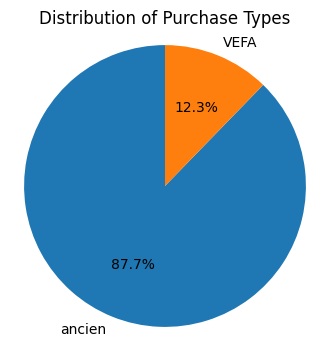

In [ ]:
type_purchase_counts = df['type_purchase'].value_counts()
plt.figure(figsize=(4, 4))  # Adjust figure size if needed
plt.pie(type_purchase_counts, labels=type_purchase_counts.index, autopct='%1.1f%%', startangle=90)
plt.title('Distribution of Purchase Types')
plt.axis('equal')
plt.savefig('/content/drive/MyDrive/TEIAS/ADS/Project/type_purchase_pie_chart.png') # Save the chart
plt.show()

**type_property:**

it's a 2-state factor variable with values "appartement" and "maison"

In [ ]:
df.type_property.value_counts()

,count
type_property,
appartement,39700
maison,673


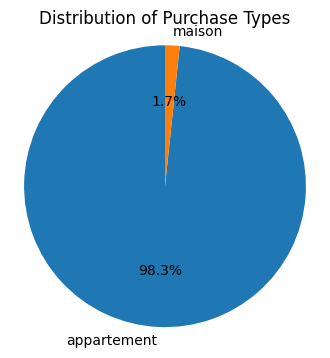

In [ ]:
type_property_counts = df['type_property'].value_counts()
plt.figure(figsize=(4, 4))  # Adjust figure size if needed
plt.pie(type_property_counts, labels=type_property_counts.index, autopct='%1.1f%%', startangle=90)
plt.title('Distribution of Purchase Types')
plt.axis('equal')
plt.savefig('/content/drive/MyDrive/TEIAS/ADS/Project/type_property_pie_chart.png') # Save the chart
plt.show()

In [ ]:
fig = px.scatter_mapbox(df, lat="latitude", lon="longitude", color="type_property", zoom=11,
                        mapbox_style="carto-positron")
fig.update_layout(margin={"r":0,"t":0,"l":0,"b":0})
fig.show()

**rooms_count:**
it's an integer value variable ranges from 1 to 6 rooms.

rooms_count
3    12576
2    10929
4     7765
1     6007
5     2518
6      578
Name: count, dtype: int64


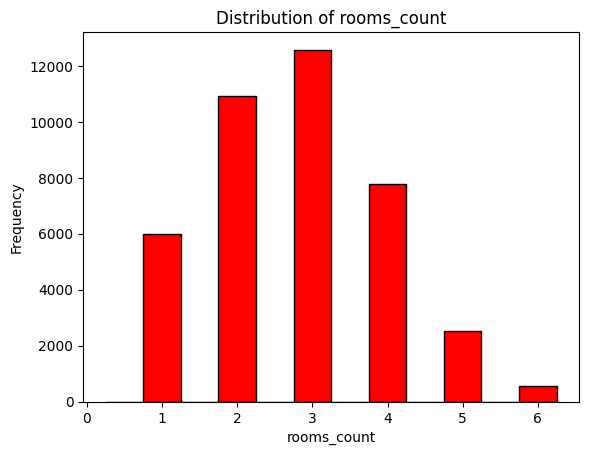

In [ ]:
# value counts
rooms_counts = df['rooms_count'].value_counts()
print(rooms_counts)

# Plot histogram
breaks = np.arange(0.25, 6.5 , 0.5)
plt.hist(df['rooms_count'], bins=breaks, color='red', edgecolor='black')
plt.title("Distribution of rooms_count")
plt.xlabel("rooms_count")
plt.ylabel("Frequency")
plt.show()

**surface_housing:**

It's an integer value variable ranges from 20 to 300

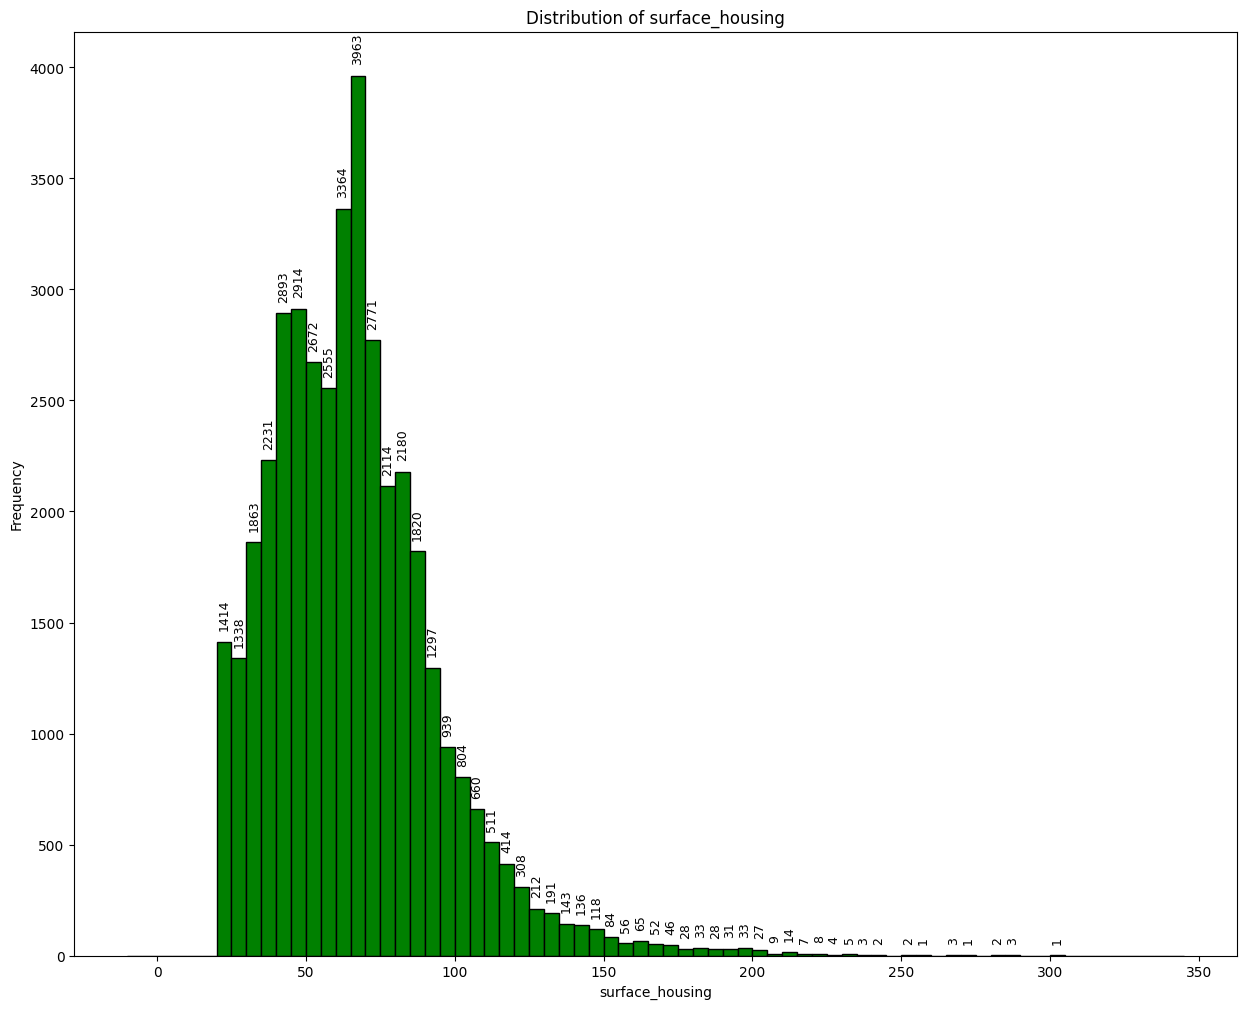

In [ ]:
# Plot histogram
plt.figure(figsize=(15, 12))
counts, bins, bars = plt.hist(df['surface_housing'], bins=range(-10,350 , 5), color='green', edgecolor='black')

# Add frequency labels above each bar
for bar, count in zip(bars, counts):
    height = bar.get_height()
    if height > 0:  # Only label bars with a height greater than 0
        plt.text(bar.get_x() + bar.get_width() / 2, height + 50,  # x and y position
                 str(int(count)),  # Convert count to integer
                 ha='center', va='bottom', fontsize=9, color='black' , rotation=90)  # Center-aligned

# Title and labels
plt.title("Distribution of surface_housing")
plt.xlabel("surface_housing")
plt.ylabel("Frequency")
plt.show()

the mean and standard error of this column is:

Mean of surface_housing: 65.22185619101874
Standard deviation of surface_housing: 28.224819570063804


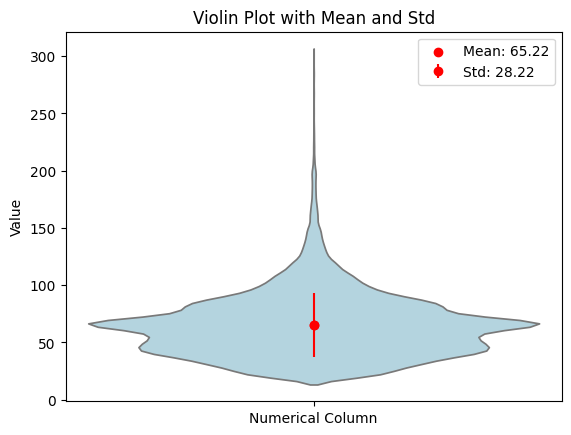

In [ ]:
# Calculate the mean and standard deviation of 'surface_housing'
mean_surface_housing = df['surface_housing'].mean()
std_surface_housing = df['surface_housing'].std()

print(f"Mean of surface_housing: {mean_surface_housing}")
print(f"Standard deviation of surface_housing: {std_surface_housing}")

# violin plot
sns.violinplot(data=df['surface_housing'], inner=None, color="lightblue")
plt.scatter(0, mean_surface_housing, color="red", label=f"Mean: {mean_surface_housing:.2f}")
plt.errorbar(0, mean_surface_housing, yerr=std_surface_housing, fmt="o", color="red", label=f"Std: {std_surface_housing:.2f}")

# Add labels and title
plt.title("Violin Plot with Mean and Std")
plt.xticks([0], ["Numerical Column"])
plt.ylabel("Value")
plt.legend()

plt.show()

now if we plot it and match a normal curve on it :

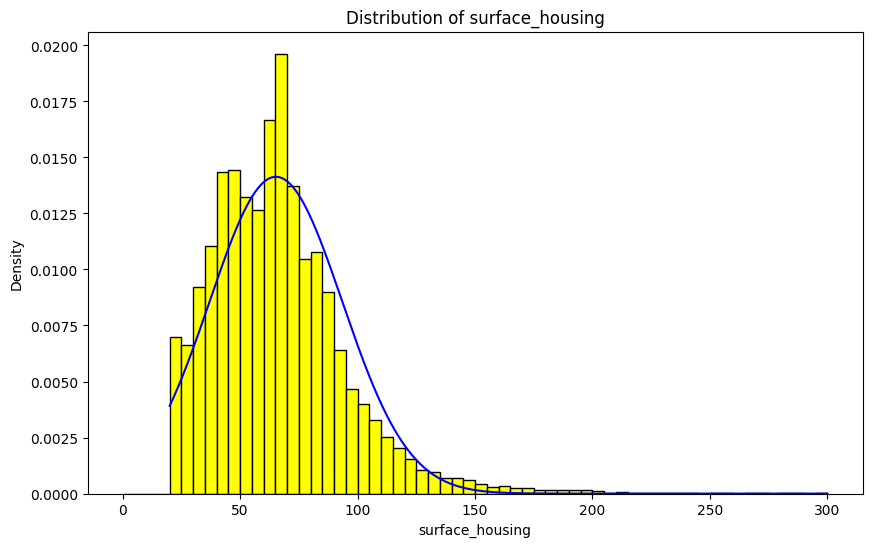

In [ ]:

surface_housing = df['surface_housing'].values

# Calculate mean and standard deviation
mea = np.mean(surface_housing)
s = np.std(surface_housing)

plt.figure(figsize=(10, 6))

# Create histogram with custom breaks
plt.hist(surface_housing, bins=np.arange(0, 305, 5), color='yellow', edgecolor='black', density=True)

# Fit a normal distribution
xfit = np.linspace(min(surface_housing), max(surface_housing), len(surface_housing))
# Use loc for mean and scale for standard deviation
yfit = norm.pdf(xfit, loc=mea, scale=s)

# Plot the normal curve on top of the histogram
plt.plot(xfit, yfit, color='blue')

# Set title and labels
plt.title("Distribution of surface_housing")
plt.xlabel("surface_housing")
plt.ylabel("Density")

# Show the plot
plt.show()

**surface_terrain:**

It's an integer value variable ranges from 0 to 900. if we plot :

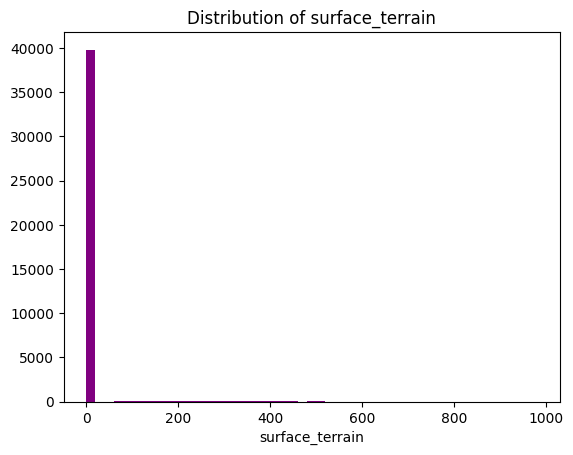

In [ ]:
surface_terrain = df['surface_terrain'].values

# Create histogram
plt.hist(surface_terrain, bins=np.arange(0, 1000, 20), color='purple')

# Set title and labels
plt.title("Distribution of surface_terrain")
plt.xlabel("surface_terrain")

# Show the plot
plt.show()

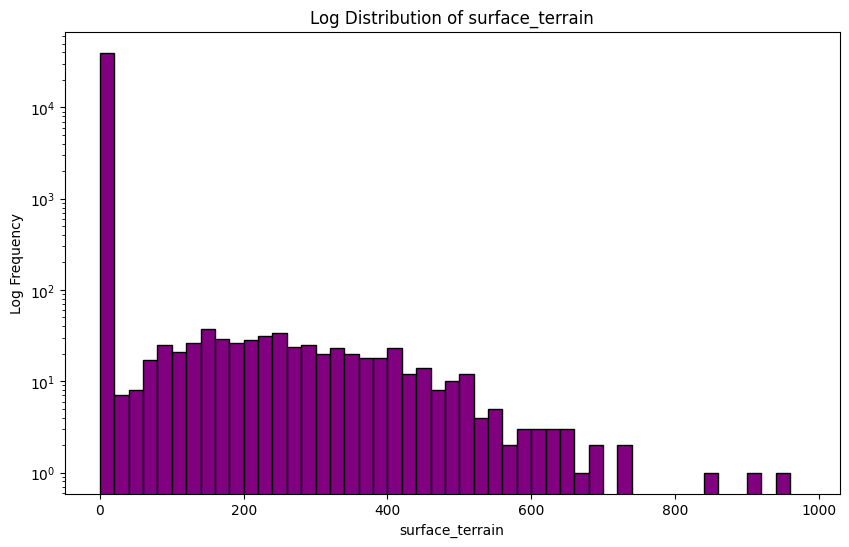

In [ ]:
# plot log of the above histogram. log the frrequency

surface_terrain = df['surface_terrain'].values

plt.figure(figsize=(10, 6))
# Create histogram with log scaling on the y-axis
plt.hist(surface_terrain, color='purple',  bins=np.arange(0, 1000, 20),  edgecolor='black', log=True) # log=True applies log scaling to the y-axis (frequency)

# Set title and labels
plt.title("Log Distribution of surface_terrain")
plt.xlabel("surface_terrain")
plt.ylabel("Log Frequency")

# Show the plot
plt.show()

it seems strange!. lets see how many houses have a yard(e.g have non-zero surface_terrain area)

In [ ]:
# Count zero vs. non-zero surface_terrain
zero_terrain = df[df['surface_terrain'] == 0].shape[0]
non_zero_terrain = df[df['surface_terrain'] != 0].shape[0]

print(f"Number of houses with zero surface_terrain: {zero_terrain}")
print(f"Number of houses with non-zero surface_terrain: {non_zero_terrain}")

Number of houses with zero surface_terrain: 39825
Number of houses with non-zero surface_terrain: 548


so about 1.4% of the houses has a yard!!!
let's have look at distribution of non-zero ones :

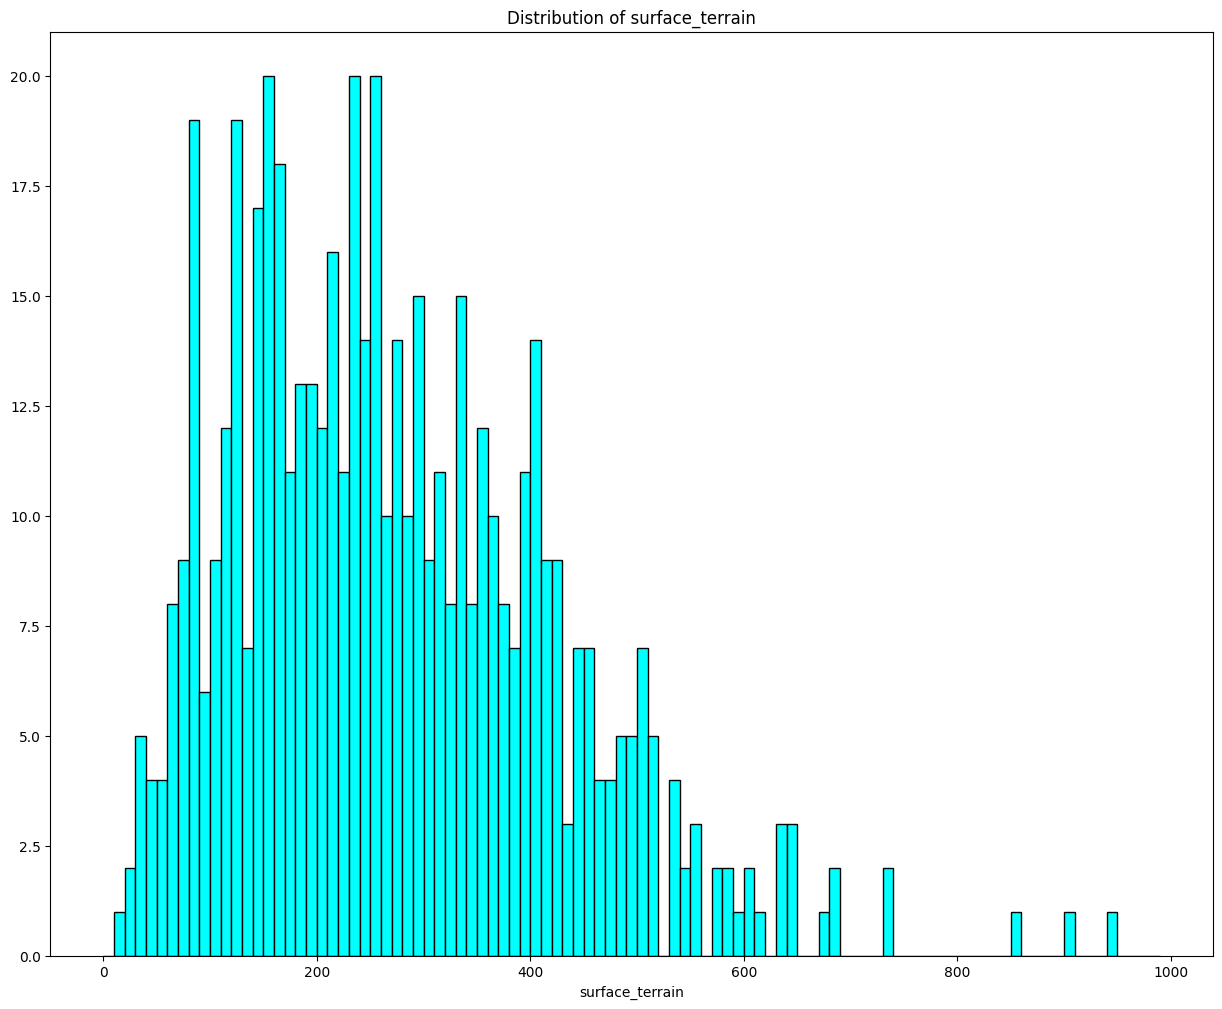

In [ ]:
t2 = df[df['surface_terrain'] > 0]

plt.figure(figsize=(15, 12))

# Create histogram on the y-axis
plt.hist(t2['surface_terrain'], color='cyan',  bins=np.arange(0, 1000, 10),  edgecolor='black')

# Set title and labels
plt.title("Distribution of surface_terrain")
plt.xlabel("surface_terrain")

# Show the plot
plt.show()

**parkings_count:**

it's an integer value variable ranges from 0 to 3

In [ ]:
df['parkings_count'].value_counts()

,count
parkings_count,
1,19817
0,18469
2,1903
3,184


**price:**

it's a float value variable ranges from 24000.00 to 2780000.00.
if we draw histogram of houses with respect to their price :

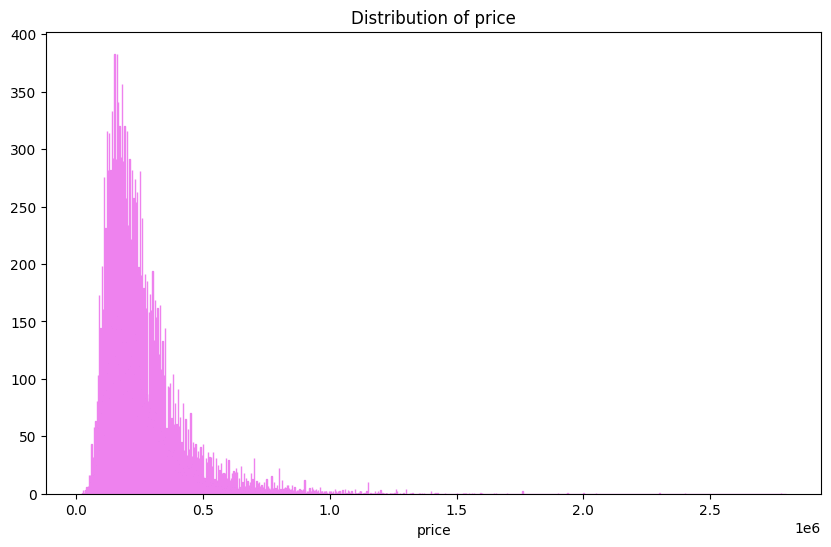

In [ ]:
plt.figure(figsize=(10, 6))
plt.hist(df['price'], bins=range(20000, 2800000, 1000), edgecolor='violet')
plt.title("Distribution of price")
plt.xlabel("price")
plt.show()


it seems it has a lot of outliers. (I conclude it from the shape of distribution, which is right-skewed!).

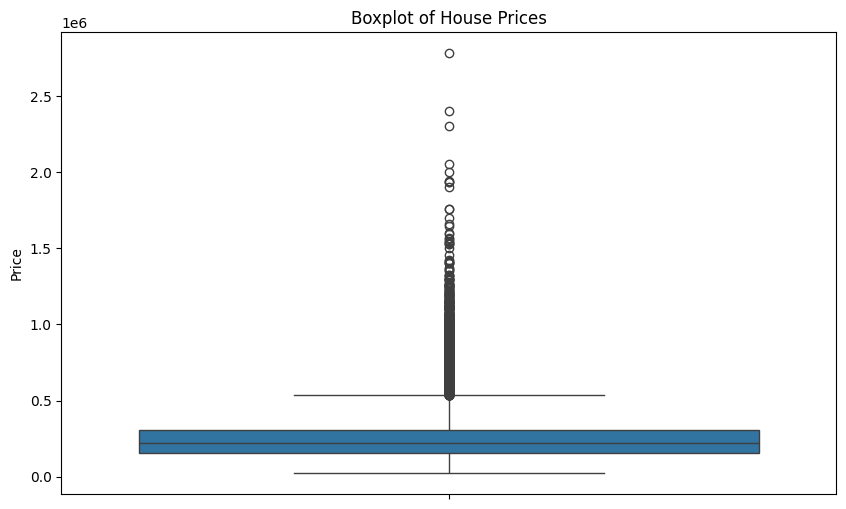

In [ ]:
# boxplot price

plt.figure(figsize=(10, 6))
sns.boxplot(y=df['price'])
plt.title('Boxplot of House Prices')
plt.ylabel('Price')
plt.show()

If we count number of outliers:

In [ ]:
# count outliers

# Calculate the first quartile (Q1) and third quartile (Q3)
Q1 = df['price'].quantile(0.25)
Q3 = df['price'].quantile(0.75)

# Calculate the interquartile range (IQR)
IQR = Q3 - Q1

# Define the lower and upper bounds for outliers
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

# Count outliers
outliers_count = df[(df['price'] < lower_bound) | (df['price'] > upper_bound)].shape[0]

print(f"Number of outliers in 'price': {outliers_count}")

Number of outliers in 'price': 2061


so the number of outlier samples is small.(in relative to all samples).
let's see how these outlier affect the mean of price :

In [ ]:
# effect of outliers on mean price

# Calculate the mean price with and without outliers
mean_price_with_outliers = df['price'].mean()
df_no_outliers = df[(df['price'] >= lower_bound) & (df['price'] <= upper_bound)]
mean_price_without_outliers = df_no_outliers['price'].mean()

# Print the results
print(f"Mean price with outliers: {mean_price_with_outliers}")
print(f"Mean price without outliers: {mean_price_without_outliers}")

# Calculate the difference
difference = mean_price_with_outliers - mean_price_without_outliers
print(f"Difference in mean price: {difference}")

Mean price with outliers: 255835.23907116143
Mean price without outliers: 230518.38843234497
Difference in mean price: 25316.850638816453


25K$ is a huge difference! The outliers have a meaningful effects,

**address:**

It's character value variable. We have removed this column.

**district:**

 It's a 10-state factor variable showing districts of lyon.
 let's see distribution of houses according to these districts:

In [ ]:
df['district'].value_counts()

,count
district,
Villeurbanne,10300
Lyon 3e Arrondissement,5967
Lyon 7e Arrondissement,5264
Lyon 8e Arrondissement,4602
Lyon 9e Arrondissement,3309
Lyon 5e Arrondissement,2933
Lyon 6e Arrondissement,2451
Lyon 4e Arrondissement,2273
Lyon 1er Arrondissement,1819


**latitude, longitude:**

float value variables showing location of the house. Let's plot each house based on it's location on the map:

In [ ]:

fig = px.scatter_mapbox(df, lat="latitude", lon="longitude", color="district", zoom=11,
                        mapbox_style="carto-positron",
                        hover_name="district")
fig.update_layout(margin={"r":0,"t":0,"l":0,"b":0})
fig.show()

This plot also helps haveing a better understanding of lyon's districts.

**date_construction:**

Shows time of construction. By using construction_year which we have added to the dataset in the begining, we plot a histogram :

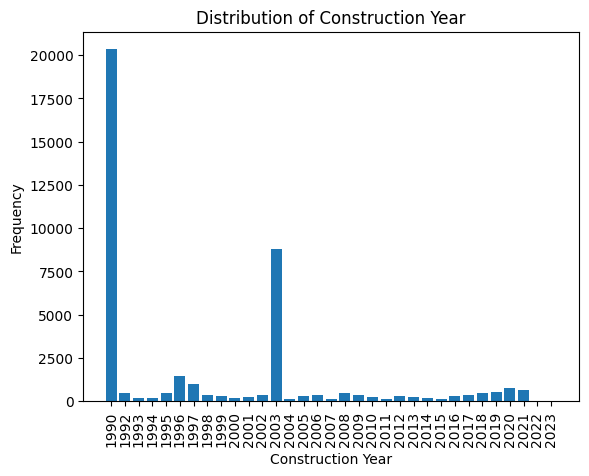

In [ ]:
# Get unique construction years and their frequencies
unique_years, frequencies = np.unique(df['cons_year'], return_counts=True)

# Create a bar plot with x-axis sorted based on construction year
plt.bar(unique_years, frequencies)

plt.xlabel("Construction Year")
plt.ylabel("Frequency")
plt.title("Distribution of Construction Year")
plt.xticks(rotation=90)
plt.show()

wait what ?! constuction date of some the house is for future :| (year 2022 and 2023!)
let's count them!

In [ ]:
df['cons_year'] = df['cons_year'].astype(str)
df['cons_year'] = pd.to_numeric(df['cons_year'])
df['cons_month'] = pd.to_numeric(df['cons_month'])
df[((df['cons_year'] == 2021) & (df['cons_month'] > 7) & (df['type_purchase'] != 'VEFA')) | (df['cons_year'] > 2021)]['cons_year'].value_counts().sort_index()    # all dates after 2021/06/30 are invalid


,count
cons_year,
2021,55
2022,13
2023,6


maybe some of these values are invalid dates (e.g construction date later than 2021/06/30 and they are not "VEFA" ):

In [ ]:
# Calculate the sum of rows meeting the conditions
result = df[((df['cons_year'] == 2021) & (df['cons_month'] > 7) & (df['type_purchase'] != 'VEFA')) | (df['cons_year'] > 2021)]

# Print the result
print(result.shape[0])

# Convert columns back to original data types (if needed)
df['cons_year'] = df['cons_year'].astype(str)
df['cons_month'] = df['cons_month'].astype(str)

74


In [ ]:
# inconsistent houses!
result

,date_transaction,type_purchase,type_property,rooms_count,surface_housing,surface_terrain,parkings_count,price,district,latitude,longitude,date_construction,year,month,day,cons_year,cons_month,cons_day,age_days,station_distance
404,2020-03-03,ancien,maison,3,121,0,0,266100.0,Villeurbanne,45.784702,4.902381,2023-04-12 11:38:00,2020,3,3,2023,4,12,-1136,1.599915
640,2020-02-11,ancien,maison,3,70,0,0,384000.0,Villeurbanne,45.770101,4.899641,2022-05-09 11:38:00,2020,2,11,2022,5,09,-819,0.504424
2071,2020-12-29,ancien,appartement,2,26,0,1,131779.2,Villeurbanne,45.778061,4.878493,2023-01-25 11:38:00,2020,12,29,2023,1,25,-758,0.334841
2072,2021-02-15,ancien,appartement,2,26,0,0,130263.4,Villeurbanne,45.778061,4.878493,2023-01-25 11:38:00,2021,2,15,2023,1,25,-710,0.334841
2790,2019-10-15,ancien,appartement,5,109,0,1,407600.0,Villeurbanne,45.771272,4.881421,2021-12-01 11:38:00,2019,10,15,2021,12,01,-779,0.256113
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
32883,2020-09-14,ancien,appartement,2,48,0,3,248185.0,Lyon 8e Arrondissement,45.742244,4.873812,2023-06-07 11:38:00,2020,9,14,2023,6,07,-997,0.229766
33358,2019-11-07,ancien,appartement,2,47,0,0,155000.0,Lyon 8e Arrondissement,45.739632,4.878786,2021-12-01 11:38:00,2019,11,7,2021,12,01,-756,0.342971
33359,2019-11-22,ancien,appartement,2,42,0,0,143010.0,Lyon 8e Arrondissement,45.739632,4.878786,2021-12-01 11:38:00,2019,11,22,2021,12,01,-741,0.342971
33360,2019-12-10,ancien,appartement,4,84,0,0,215000.0,Lyon 8e Arrondissement,45.739632,4.878786,2021-12-01 11:38:00,2019,12,10,2021,12,01,-723,0.342971


it seems that these dates are wrong and invalid.(74 invalid dates) so we should be aware of this in later calculations.

In [ ]:
# remove reslut from df

# Get the indices of rows to be removed from 'df'
indices_to_remove = df.index.isin(result.index)

# Remove those rows from 'df'
df = df[~indices_to_remove]

# Now 'df' does not contain the rows that were in 'result'
df.shape

(40299, 20)

Plot houses based on the construction year

In [ ]:

fig = px.scatter_mapbox(df, lat="latitude", lon="longitude", color="cons_year", zoom=11,
                        mapbox_style="carto-positron")
fig.update_layout(margin={"r":0,"t":0,"l":0,"b":0})
fig.show()

it seems that the city can be divided in two parts of old-built and new-built houses. (Again, pay attention that the construction time of many houses in this dataset is 1990/01/01, due to insufficient information.)


## other useful data:

let's have a look at number of transaction per year :

In [ ]:
df['year'].value_counts()

,count
year,
2017,10004
2018,8644
2019,8461
2020,6541
2016,4323
2021,2326


as you can see, most of transactions take place in 2017 and year 2021 has the least transaction count.(we should notice that our data for years 2016 and 2021 covers only 6 month of each year, but for other years, all 12 months are covered.)

let's have a look at number of transaction per year & transaction. :

In [ ]:
pd.crosstab(df['district'], df['year'])

year,2016,2017,2018,2019,2020,2021
district,,,,,,
Lyon 1er Arrondissement,207,364,376,379,321,161
Lyon 2e Arrondissement,139,308,293,305,256,127
Lyon 3e Arrondissement,701,1437,1276,1299,980,271
Lyon 4e Arrondissement,255,496,478,461,368,213
Lyon 5e Arrondissement,304,649,596,614,509,258
Lyon 6e Arrondissement,271,618,509,525,432,96
Lyon 7e Arrondissement,530,1541,1109,1010,828,234
Lyon 8e Arrondissement,476,1150,964,1055,757,195
Lyon 9e Arrondissement,341,845,698,578,559,288


let's calculate mean of transaction price of each district according to different years :

In [ ]:
# Calculate the mean transaction price for each district and year
mean_price_by_district_year = df.groupby(['district', 'year'])['price'].mean().unstack()

# Display the result
mean_price_by_district_year

year,2016,2017,2018,2019,2020,2021
district,,,,,,
Lyon 1er Arrondissement,225877.406377,265992.534698,288503.211277,299805.836148,326696.006231,351172.832298
Lyon 2e Arrondissement,317490.529928,332740.953442,348187.141195,353785.160000,404719.820117,441675.196850
Lyon 3e Arrondissement,228672.699287,249749.255658,261974.989114,285505.481932,325168.292898,331594.517528
Lyon 4e Arrondissement,288027.145098,291769.064516,336038.329916,342184.624729,376105.592609,385561.618873
Lyon 5e Arrondissement,217642.792895,220423.956040,235226.727634,264649.029153,276494.974735,311716.317364
Lyon 6e Arrondissement,315191.339262,352807.132573,377342.832259,429051.536667,477132.278125,437025.531250
Lyon 7e Arrondissement,215725.677736,221528.508650,252887.892453,255362.869624,289085.729746,298174.858333
Lyon 8e Arrondissement,201843.284244,216554.778626,214956.644637,231811.631384,260948.999472,283050.071795
Lyon 9e Arrondissement,198912.577185,200852.104225,208967.469241,228671.743841,246026.059928,249811.518889


 it seems that district "Villeurbanne" has the lowest prices(actually mean of prices) and district "Lyon 6e Arrondissement" has the highest prices.




 now if we plot this table, we can see increase and decreases in price in another format :

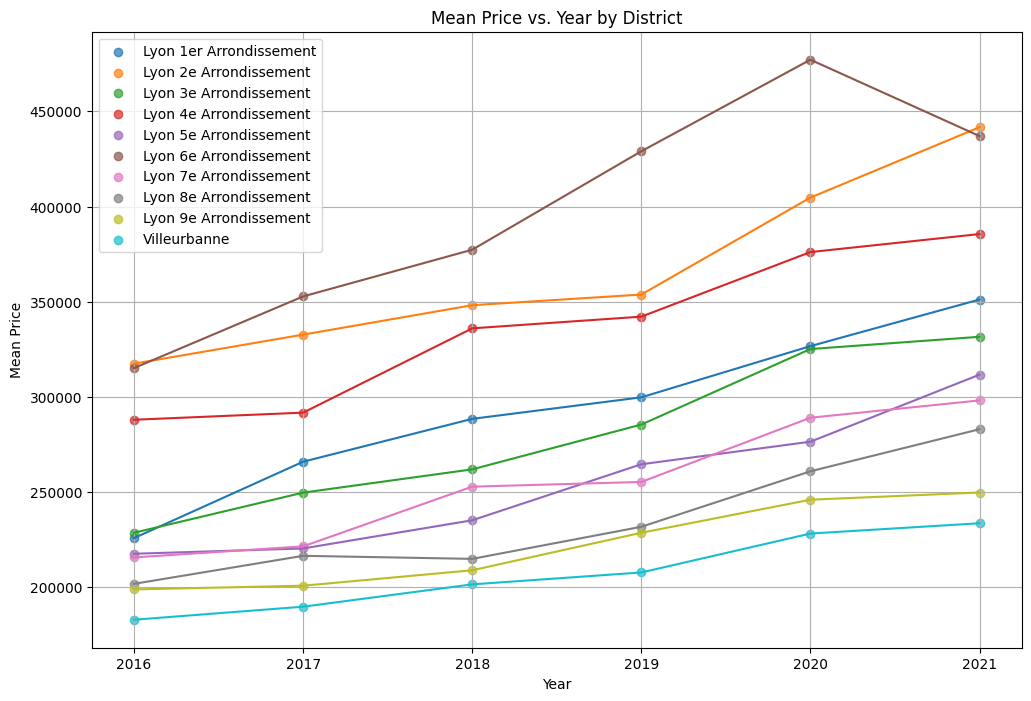

In [ ]:
mean_price_by_district_year = df.groupby(['district', 'year'])['price'].mean().reset_index()

plt.figure(figsize=(12, 8))  # Adjust figure size for better visibility

for district in mean_price_by_district_year['district'].unique():
    district_data = mean_price_by_district_year[mean_price_by_district_year['district'] == district]
    plt.scatter(district_data['year'], district_data['price'], label=district, alpha=0.7)  # Adjust alpha for better overlap visualization
    plt.plot(district_data['year'], district_data['price'])  # Add line plot

plt.xlabel('Year')
plt.ylabel('Mean Price')
plt.title('Mean Price vs. Year by District')
plt.legend()  # Show legend for districts
plt.grid(True) # Add grid lines
plt.show()

now, as we promised, if we plot a map of houses according to their location with respect to their year of transaction :

In [ ]:
df['year'] = df['year'].astype('category')

fig = px.scatter_mapbox(df, lat="latitude", lon="longitude", color="year", zoom=11,
                        mapbox_style="carto-positron")
fig.update_layout(margin={"r":0,"t":0,"l":0,"b":0})
fig.show()

## FIND RELATION BETWEEN COLUMNS

let's plot a heatmap which shows the correlations between columns of the dataset. we just use numerical columns :

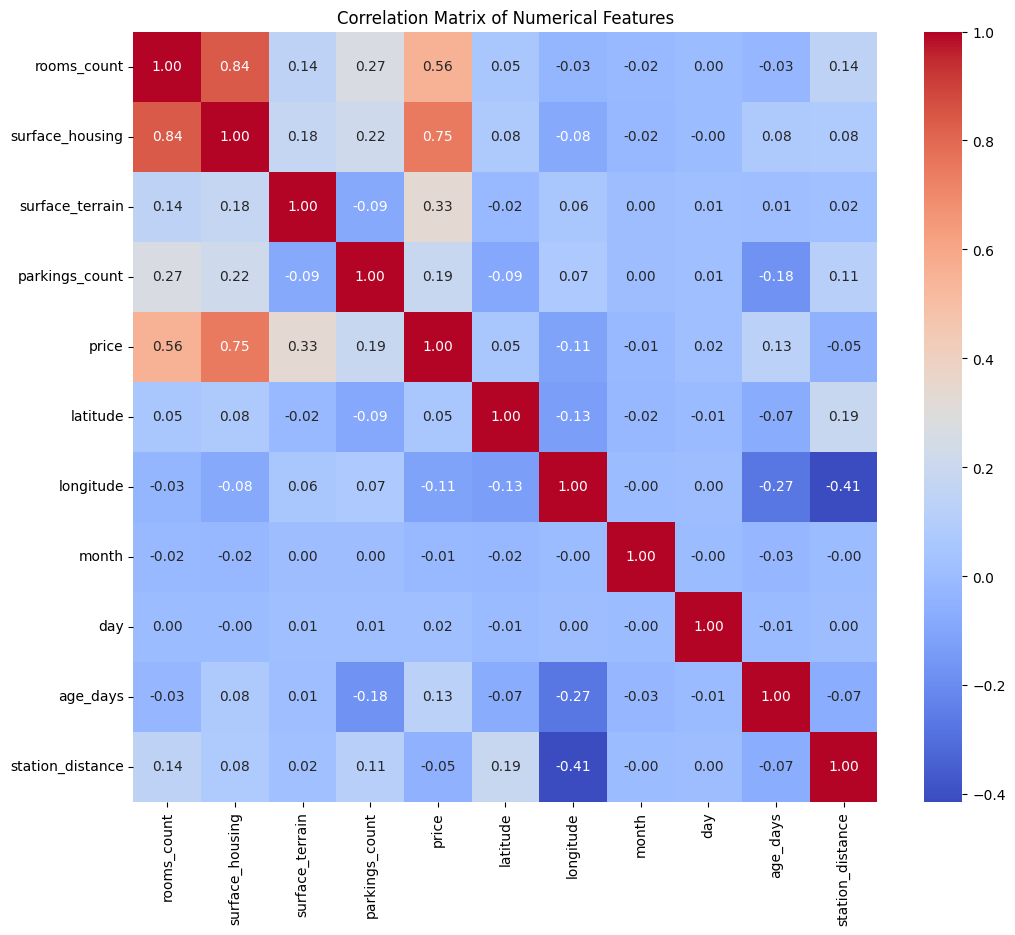

In [ ]:
numeric_cols = df.select_dtypes(include=np.number).columns
corr_matrix = df[numeric_cols].corr()

plt.figure(figsize=(12, 10))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Correlation Matrix of Numerical Features')
plt.show()

now let's investigate this heatmap.

1- it seems that "rooms_count" and "surface_housing" are positively correlated (0.84). it seems logical: as number of rooms grow, total area covered by the house will increase.

2- another noticeable correlation, is between "price" and "surface_housing". it is also reasonable to think that the vaster a house is, the more expensive it becomes.

3- another noticeable correlation, is between "price" and "rooms_count". with conclusions above, it's reasonable to think with more rooms, there will be more area covered by the house , and the vaster it is, the more expensive it becomes. but this correlation is less noticeable than two above.

let's plot some scatters to see :


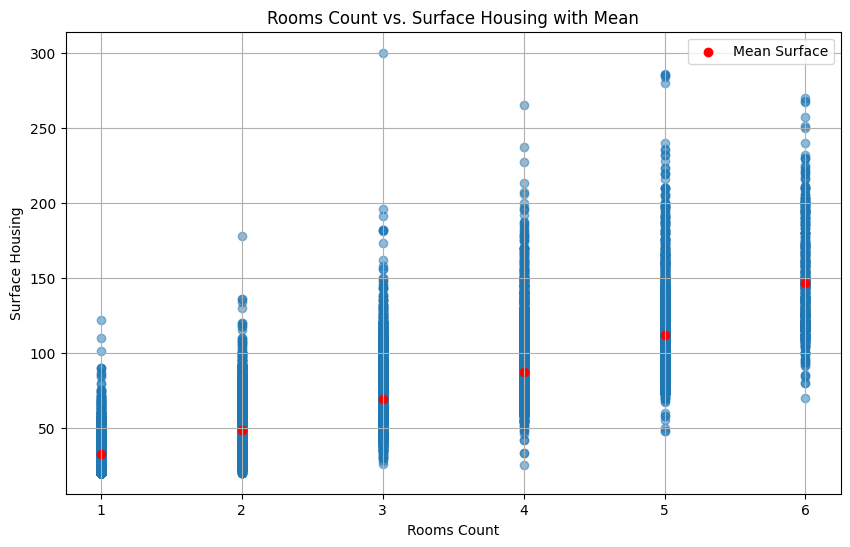

In [ ]:
# plot rooms_count vs surface_housing. add mean value of surface_housing for each rooms_count.

# Calculate the mean surface_housing for each rooms_count
mean_surface_by_rooms = df.groupby('rooms_count')['surface_housing'].mean()

# Create the scatter plot
plt.figure(figsize=(10, 6))
plt.scatter(df['rooms_count'], df['surface_housing'], alpha=0.5)  # Adjust alpha for better visualization

# Add the mean values as points
plt.scatter(mean_surface_by_rooms.index, mean_surface_by_rooms.values, color='red', label='Mean Surface')

# Add labels and title
plt.xlabel('Rooms Count')
plt.ylabel('Surface Housing')
plt.title('Rooms Count vs. Surface Housing with Mean')
plt.legend()
plt.grid(True)  # Add grid for better readability
plt.show()

now we can see the correlation better. the red dots are mean of surface_housing in each row. so we can see that when number of rooms increases, surface_housing increase too.

2-

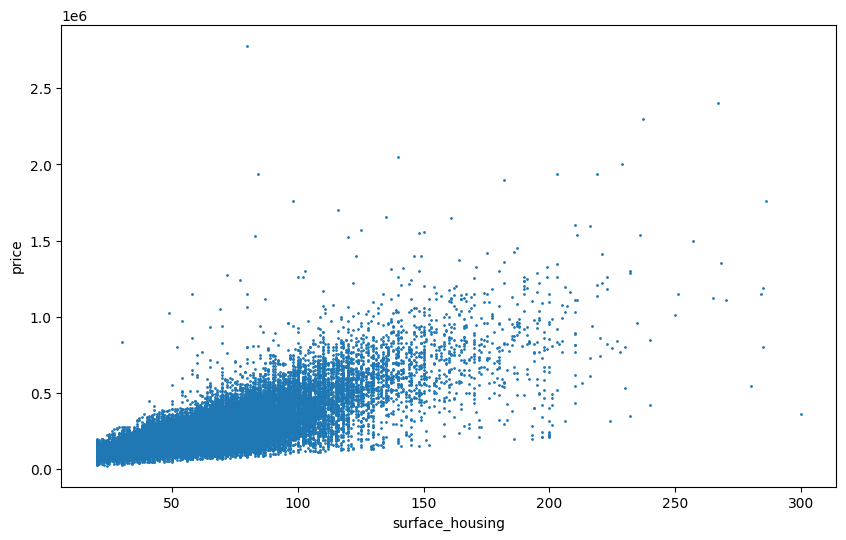

In [ ]:
plt.figure(figsize=(10, 6))
plt.scatter(df['surface_housing'], df['price'], s=1)  # s=1 sets the point size
plt.xlabel("surface_housing")
plt.ylabel("price")
plt.show()

it seems that the price of a house grows as surface of the house grows.(in total, some outliers may not behave like this.)

## ADD EXTRA COLUMNS :
we have added some columns in the beginning of our work. here we add another column :

let's see how much does 1m^2 area cost(e.g land price) for each house?

In [ ]:
df['area_price_ratio'] = df['price'] / df['surface_housing']

let's plot map of all houses again. this time color of each point will reflect the area_price_ratio

In [ ]:
df['year'] = df['year'].astype('category')

fig = px.scatter_mapbox(df, lat="latitude", lon="longitude", color="area_price_ratio", zoom=11,color_continuous_scale="RdBu",
                        mapbox_style="carto-positron")
fig.update_layout(margin={"r":0,"t":0,"l":0,"b":0})
fig.show()

in the end let's plot another figure :
this figure will show how "area_price_ratio" changed during time for each district.

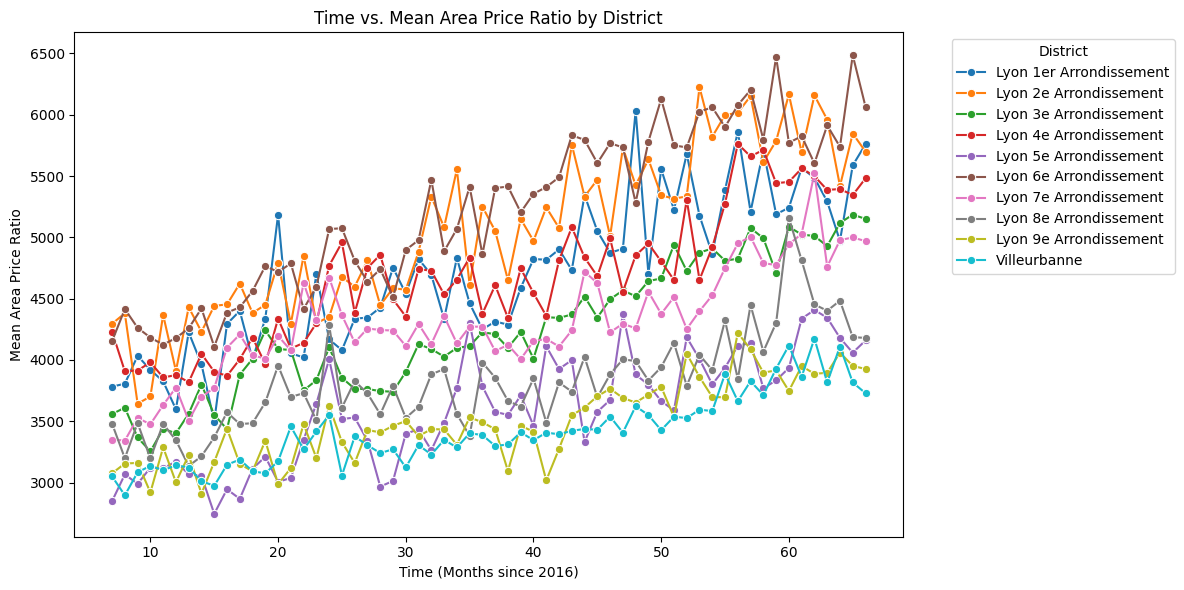

In [ ]:
# Initialize variables
districts = [
    "Lyon 1er Arrondissement", "Lyon 2e Arrondissement",
    "Lyon 3e Arrondissement", "Lyon 4e Arrondissement",
    "Lyon 5e Arrondissement", "Lyon 6e Arrondissement",
    "Lyon 7e Arrondissement", "Lyon 8e Arrondissement",
    "Lyon 9e Arrondissement", "Villeurbanne"
]

years = ["2016", "2017", "2018", "2019", "2020", "2021"]
months = ["01", "02", "03", "04", "05", "06", "07", "08", "09", "10", "11", "12"]

means = []
dis = []
yearss = []
months_numeric = []

# Nested loops for calculations
for di in districts:
    for ye in years:
        for mo in months:
            # Calculate mean of `area_price_ratio` for the specific district, year, and month
            filtered = df[(df['year'] == int(ye)) & (df['month'] == int(mo)) & (df['district'] == di)]
            t = filtered['area_price_ratio'].mean() if not filtered.empty else np.nan

            # Append values
            means.append(t)
            dis.append(di)
            yearss.append(int(ye) - 2016)
            months_numeric.append(int(mo))

# Calculate time (in months since 2016)
time = [12 * year + month for year, month in zip(yearss, months_numeric)]

# Create DataFrame
nbv = pd.DataFrame({
    'means': means,
    'dis': dis,
    'yearss': yearss,
    'months': months_numeric,
    'time': time
})

# Remove rows with NaN values
nbv2 = nbv.dropna()

# Plot using seaborn
plt.figure(figsize=(12, 6))
sns.lineplot(data=nbv2, x='time', y='means', hue='dis', marker='o')
plt.title('Time vs. Mean Area Price Ratio by District')
plt.xlabel('Time (Months since 2016)')
plt.ylabel('Mean Area Price Ratio')
plt.legend(title='District', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()


in this figure , we set 2016/1 (jan) to be 1 and for each month of each yaer we calculate time = 12*(year-2016) + month.
then calculate mean of (area_price_ratio) of that time for each district.
and then plot.













## Final modifications

First we remove timestamp columns:


In [ ]:
#remove timestamp columns
df = df.drop(['date_transaction', 'date_construction'], axis=1, errors='ignore')

Then we will convert categorical variables to numerical, since most of learning algorithms only work with numerical featues.


In [ ]:
# Convert categorical columns to numerical using one-hot encoding
df = pd.get_dummies(df, columns=['type_purchase', 'type_property'], drop_first=True)


In [ ]:
# label encode district


# Create a LabelEncoder object
label_encoder = LabelEncoder()

# Fit and transform the 'district' column
df['district'] = label_encoder.fit_transform(df['district'])

print(df['district'].value_counts())

district
9    10289
2     5964
6     5252
7     4597
8     3309
4     2930
5     2451
3     2271
0     1808
1     1428
Name: count, dtype: int64


In [ ]:
# Convert specified columns to integers. Handle potential errors gracefully.
for col in ['year', 'month', 'day', 'cons_year', 'cons_month', 'cons_day']:
        df[col] = pd.to_numeric(df[col], errors='coerce').astype('Int64') # Use 'Int64' for nullable integer type

In [ ]:
# Assuming 'df' is your DataFrame as defined in the provided code.
df = df.drop('area_price_ratio', axis=1)

In [ ]:
df.head()

,rooms_count,surface_housing,surface_terrain,parkings_count,price,district,latitude,longitude,year,month,day,cons_year,cons_month,cons_day,age_days,station_distance,type_purchase_ancien,type_property_maison
0,5,100,247,0,530000.0,9,45.781673,4.879333,2019,10,31,2003,6,11,5985,0.097081,True,True
1,2,52,156,0,328550.0,9,45.783240,4.884683,2018,11,26,2003,6,11,5646,0.442175,True,True
2,1,28,0,1,42500.0,9,45.781488,4.883474,2016,8,4,2003,6,11,4802,0.283035,True,False
3,3,67,0,1,180900.0,9,45.781488,4.883474,2016,11,18,2003,6,11,4908,0.283035,True,False
4,1,28,0,1,97000.0,9,45.781488,4.883474,2016,12,16,2003,6,11,4936,0.283035,True,False


# <font face="Verdana" color="Blue" size="+3">**2. Train Models** </font>

In the following section, we will develop and train several learning models, from simple linear regression to Neural networks, and compare their performance.

So far, we have performed EDA on the dataset. Next, we need to split the dataset into training and test set.

Finally, I might do some funny stuff in the middle of the project, for example I might examine the effect of random seed on the evaluation metrics of our models.


## Train-Test Split


In [ ]:
# stratify train-test split stratify over 'district' to keep the distribution of houses in each district in train and test set.

X = df.drop('price', axis=1)
y = df['price']

# Split the data into training and testing sets, stratifying by 'district'
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=X['district'])

## Evaluation metrics

To evaluate the performance of our models, we will use a series of metrics, listed as follows:

### <font face="Verdana" color="Red" size="+1">**1.Mean Squared Error (MSE)** </font>


The **Mean Squared Error (MSE)** is a commonly used regression metric that measures the average squared difference between the actual and predicted values. It penalizes larger errors more than smaller ones due to squaring.

#### **Formula**:
$$
MSE = \frac{1}{n} \sum_{i=1}^n (y_i - \hat{y}_i)^2
$$

Where:
- $ n $: Number of data points  
- $ y_i $: Actual value of the $i^{th}$ data point  
- $ \hat{y}_i $: Predicted value of the $i^{th}$ data point  

### <font face="Verdana" color="Red" size="+1">**2.R-squared ($ R^2 $)** </font>

The **R-squared (Coefficient of Determination)** measures how well the regression model explains the variance in the dependent variable. It represents the proportion of the variance in the target variable that is predictable from the independent variables.

#### **Formula**:
$$
R^2 = 1 - \frac{\sum_{i=1}^n (y_i - \hat{y}_i)^2}{\sum_{i=1}^n (y_i - \bar{y})^2}
$$

Where:
- $ n $: Number of data points  
- $ y_i $: Actual value of the $i^{th}$ data point  
- $ \hat{y}_i $: Predicted value of the $i^{th}$ data point  
- $ \bar{y} $: Mean of the actual values  

#### **Key Characteristics**:
- **Range:** $ (-\infty, 1] $  
  - $ R^2 = 1 $: Perfect fit (all variance is explained by the model).  
  - $ R^2 = 0 $: Model explains no variance (same as the mean).  
  - $ R^2 < 0 $: Model performs worse than a horizontal line (mean predictor).  

#### **Interpretation**:
- A higher $ R^2 $ indicates better performance, but it does not account for model complexity or overfitting.


### <font face="Verdana" color="Red" size="+1">**3.Adjusted R-squared ($ R^2_{adj} $)** </font>  

The **Adjusted R-squared** modifies the $ R^2 $ score to account for the number of predictors in the model. Unlike $ R^2 $, it penalizes the inclusion of irrelevant predictors, preventing overfitting in models with multiple features.

#### **Formula**:
$$
R^2_{adj} = 1 - \left( \frac{(1 - R^2)(n - 1)}{n - p - 1} \right)
$$

Where:
- $ R^2 $: Regular R-squared value  
- $ n $: Number of data points  
- $ p $: Number of predictors (independent variables)  

#### **Key Characteristics**:
- **Range:** Similar to $ R^2 $, $ (-\infty, 1] $  
- **Behavior:**
  - If adding a predictor improves the model significantly, $ R^2_{adj} $ increases.
  - If the predictor adds no value, $ R^2_{adj} $ decreases compared to $ R^2 $.



### <font face="Verdana" color="Red" size="+1">**4.Root Mean Squared Error (RMSE)** </font>  

The **Root Mean Squared Error (RMSE)** is a widely used regression metric that measures the average magnitude of the errors between predicted and actual values. It is the square root of the Mean Squared Error (MSE), bringing the error back to the same unit as the target variable.

#### **Formula**:
$$
RMSE = \sqrt{MSE} = \sqrt{\frac{1}{n} \sum_{i=1}^n (y_i - \hat{y}_i)^2}
$$


In [ ]:
#a function to calculate metrics
def calculate_metrics(y_true_test, y_pred_test , y_true_train , y_pred_train , num_predictors):
  test_metrics = calculate_metrics_util(y_true_test, y_pred_test, num_predictors)
  train_metrics = calculate_metrics_util(y_true_train, y_pred_train, num_predictors)
  return test_metrics , train_metrics


def calculate_metrics_util(y_true, y_pred , num_predictors):

    mse = mean_squared_error(y_true, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_true, y_pred)

    #Adjusted R-squared calculation
    n = len(y_true)
    p = num_predictors # Number of predictors (replace this with actual number of predictors if available)
    r2_adj = 1 - ((1-r2) * (n - 1) / (n-p-1))

    metrics = {
        'MSE': mse,
        'RMSE': rmse,
        'R-squared': r2,
        'Adjusted R-squared':r2_adj
    }

    return metrics

def print_metrics(metrics):
    for metric_name, metric_value in metrics.items():
        print(f"{metric_name}: {metric_value}")

## Linear Regression

Now  that we have done the split, It's time to start the main part of the project. We start by simple Linear regression:



In [ ]:
# a reuseable method for linear regression model

def train_linear_regression(X_train, y_train, X_test, y_test):
    # Create and train the linear regression model
    model = LinearRegression()
    model.fit(X_train, y_train)

    # Make predictions on the test set
    y_pred_test = model.predict(X_test)
    y_pred_train = model.predict(X_train)


    # Evaluate the model
    test_metrics , train_metrics = calculate_metrics(y_test, y_pred_test, y_train , y_pred_train, num_predictors=X_train.shape[1])


    return model , test_metrics, train_metrics , y_pred_test , y_pred_train

Now let's see how a a linear regression model performs:

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
lr_model , lr_test_metrics , lr_train_metrics , lr_y_pred_test , lr_y_pred_train= train_linear_regression(X_train, y_train, X_test, y_test)

print("Test Metrics:")
print_metrics(lr_test_metrics)

print("\nTrain Metrics:")
print_metrics(lr_train_metrics)

Test Metrics:
MSE: 6970133807.3993435
RMSE: 83487.3272263482
R-squared: 0.7090260418777168
Adjusted R-squared: 0.7084109514414971

Train Metrics:
MSE: 6515298356.005795
RMSE: 80717.39809982601
R-squared: 0.726931493435627
Adjusted R-squared: 0.7267874207932015


### <font face="Verdana" color="Red" size="+1">**A funny test** </font>

Let's see how random seed might affect our model.



In [ ]:
test_res = []
train_res = []
random_states = range(0,100)
for random_state in random_states:
  X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=random_state)
  model , test_metrics , train_metrics, _ , _ = train_linear_regression(X_train, y_train, X_test, y_test)
  test_res.append(test_metrics['Adjusted R-squared'])
  train_res.append(train_metrics['Adjusted R-squared'])

print(f"Maximum adjusted R2 is ={max(test_res)}")
print(f"Maximum adjusted R2 is ={min(test_res)}")

Maximum adjusted R2 is =0.7437085843225426
Maximum adjusted R2 is =0.693197458412384


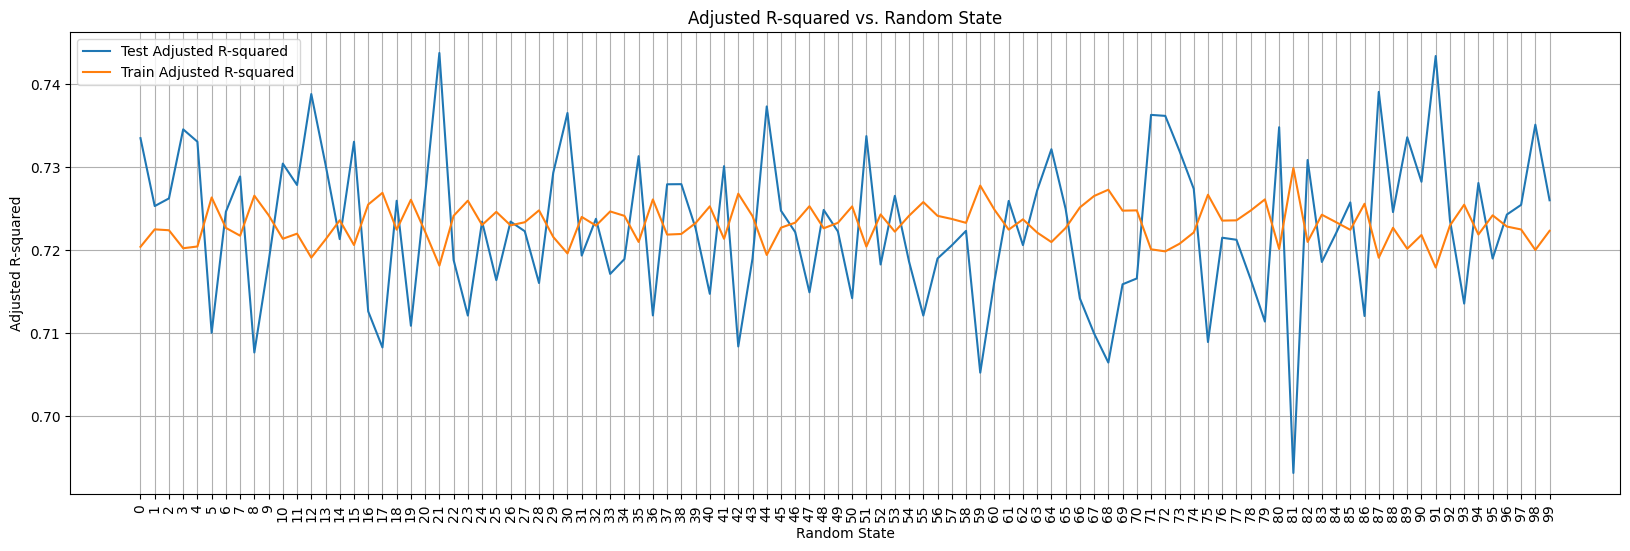

In [ ]:
plt.figure(figsize=(20, 6))
plt.plot(random_states, test_res, label='Test Adjusted R-squared')
plt.plot(random_states, train_res, label='Train Adjusted R-squared')
plt.xlabel('Random State')
plt.ylabel('Adjusted R-squared')
plt.xticks(random_states , rotation = 90)
plt.title('Adjusted R-squared vs. Random State')
plt.legend()
plt.grid(True)
plt.show()

The plot shows the Adjusted R-squared values for train and test sets across various random states used in train-test splitting. The Test Adjusted R-squared (blue line) exhibits significant variability, indicating that the model's performance on the test set is sensitive to the specific train-test split. In contrast, the Train Adjusted R-squared (orange line) remains more stable, suggesting the model's fit to the training data is less influenced by the splits. Interestingly, the Test R-squared is often higher than the Train R-squared, which may indicate good generalization but also highlights the model's susceptibility to changes in the data split. This variability suggests that the dataset may have high variance or an imbalanced distribution, leading to inconsistent test results. Using cross-validation instead of relying on individual splits could provide a more reliable evaluation of the model's performance.

### Lasso and Ridge?

In [ ]:
def train_lasso(X_train, y_train, X_test, y_test, alpha=1.0):
    model = Lasso(alpha=alpha)
    model.fit(X_train, y_train)
    y_pred_test = model.predict(X_test)
    y_pred_train = model.predict(X_train)
    test_metrics, train_metrics = calculate_metrics(y_test, y_pred_test, y_train, y_pred_train, num_predictors=X_train.shape[1])
    return model, test_metrics, train_metrics , y_pred_test , y_pred_train

def train_ridge(X_train, y_train, X_test, y_test, alpha=1.0):
    model = Ridge(alpha=alpha)
    model.fit(X_train, y_train)
    y_pred_test = model.predict(X_test)
    y_pred_train = model.predict(X_train)
    test_metrics, train_metrics = calculate_metrics(y_test, y_pred_test, y_train, y_pred_train, num_predictors=X_train.shape[1])
    return model, test_metrics, train_metrics, y_pred_test , y_pred_train

# Lasso:
lasso_model, lasso_test_metrics, lasso_train_metrics , lasso_y_pred_test , lasso_y_pred_train= train_lasso(X_train, y_train, X_test, y_test, alpha=0.00001)  # Adjust alpha as needed

print("Lasso Test Metrics:")
print_metrics(lasso_test_metrics)
print("\nLasso Train Metrics:")
print_metrics(lasso_train_metrics)

# Ridge:
ridge_model, ridge_test_metrics, ridge_train_metrics , ridge_y_pred_test , ridge_y_pred_train = train_ridge(X_train, y_train, X_test, y_test, alpha=0.00001)  # Adjust alpha as needed

print("\nRidge Test Metrics:")
print_metrics(ridge_test_metrics)
print("\nRidge Train Metrics:")
print_metrics(ridge_train_metrics)

Lasso Test Metrics:
MSE: 6760454803.059656
RMSE: 82221.98491315845
R-squared: 0.7265569275275148
Adjusted R-squared: 0.7259788956657849

Lasso Train Metrics:
MSE: 6567961190.078269
RMSE: 81042.95891734376
R-squared: 0.7224647052479889
Adjusted R-squared: 0.7223182759003342

Ridge Test Metrics:
MSE: 6760067204.122686
RMSE: 82219.62785200798
R-squared: 0.726572604911256
Adjusted R-squared: 0.7259946061899791

Ridge Train Metrics:
MSE: 6567936729.193155
RMSE: 81042.80800412307
R-squared: 0.7224657388653877
Adjusted R-squared: 0.7223193100630758


/usr/local/lib/python3.11/dist-packages/sklearn/linear_model/_coordinate_descent.py:695: ConvergenceWarning:

Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 1.059e+14, tolerance: 7.629e+10



Let's focus on Lasso for example. How does different values for alpha affect the result?


/usr/local/lib/python3.11/dist-packages/sklearn/linear_model/_coordinate_descent.py:695: ConvergenceWarning:

Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 1.058e+14, tolerance: 7.629e+10

/usr/local/lib/python3.11/dist-packages/sklearn/linear_model/_coordinate_descent.py:695: ConvergenceWarning:

Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 1.057e+14, tolerance: 7.629e+10

/usr/local/lib/python3.11/dist-packages/sklearn/linear_model/_coordinate_descent.py:695: ConvergenceWarning:

Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 1.052e+14, tolerance: 7.629e+10

/usr/local/lib/python3.11/dist-packages/sklearn/linear_model/_coordinate_des

       alpha   test_r2  train_r2
0     0.0001  0.726557  0.722465
1     0.0003  0.726557  0.722465
2     0.0010  0.726557  0.722465
3     0.0030  0.726557  0.722465
4     0.0100  0.726557  0.722465
5     0.0300  0.726558  0.722465
6     0.1000  0.726559  0.722465
7     0.3000  0.726563  0.722465
8     1.0000  0.726577  0.722464
9     3.0000  0.726615  0.722462
10   10.0000  0.726732  0.722437
11   30.0000  0.726924  0.722217
12  100.0000  0.725965  0.719798
13  300.0000  0.722283  0.714611


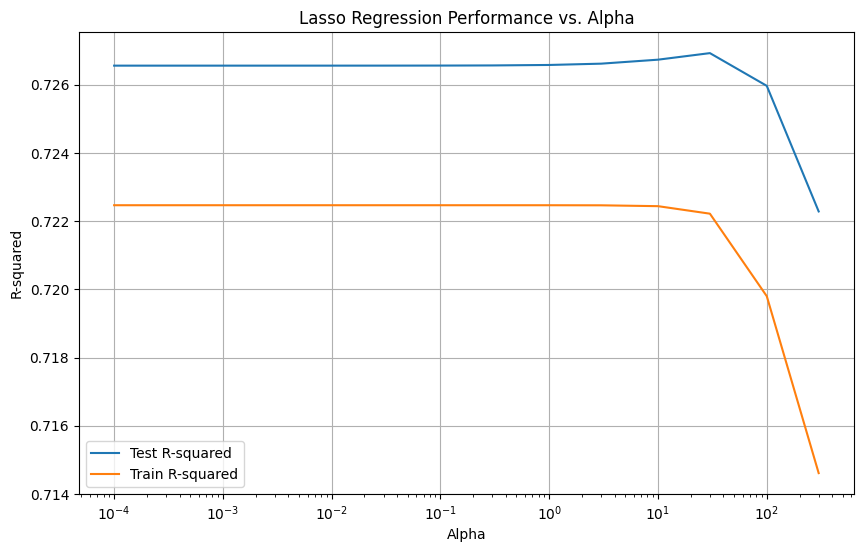

In [ ]:
alphas = [0.0001, 0.0003, 0.001, 0.003, 0.01, 0.03, 0.1, 0.3, 1, 3, 10, 30, 100, 300]
results = []

for alpha in alphas:
    lasso_model, lasso_test_metrics, lasso_train_metrics ,_ , _ = train_lasso(X_train, y_train, X_test, y_test, alpha=alpha)
    results.append({
        'alpha': alpha,
        'test_r2': lasso_test_metrics['R-squared'],
        'train_r2': lasso_train_metrics['R-squared']
    })

results_df = pd.DataFrame(results)
print(results_df)

plt.figure(figsize=(10, 6))
plt.plot(results_df['alpha'], results_df['test_r2'], label='Test R-squared')
plt.plot(results_df['alpha'], results_df['train_r2'], label='Train R-squared')
plt.xscale('log')  # Use logarithmic scale for alpha
plt.xlabel('Alpha')
plt.ylabel('R-squared')
plt.title('Lasso Regression Performance vs. Alpha')
plt.legend()
plt.grid(True)
plt.show()

/usr/local/lib/python3.11/dist-packages/sklearn/linear_model/_coordinate_descent.py:695: ConvergenceWarning:

Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 1.059e+14, tolerance: 7.629e+10

/usr/local/lib/python3.11/dist-packages/sklearn/linear_model/_coordinate_descent.py:695: ConvergenceWarning:

Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 1.770e+13, tolerance: 7.629e+10

/usr/local/lib/python3.11/dist-packages/sklearn/linear_model/_coordinate_descent.py:695: ConvergenceWarning:

Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 8.202e+12, tolerance: 7.629e+10

/usr/local/lib/python3.11/dist-packages/sklearn/linear_model/_coordinate_des

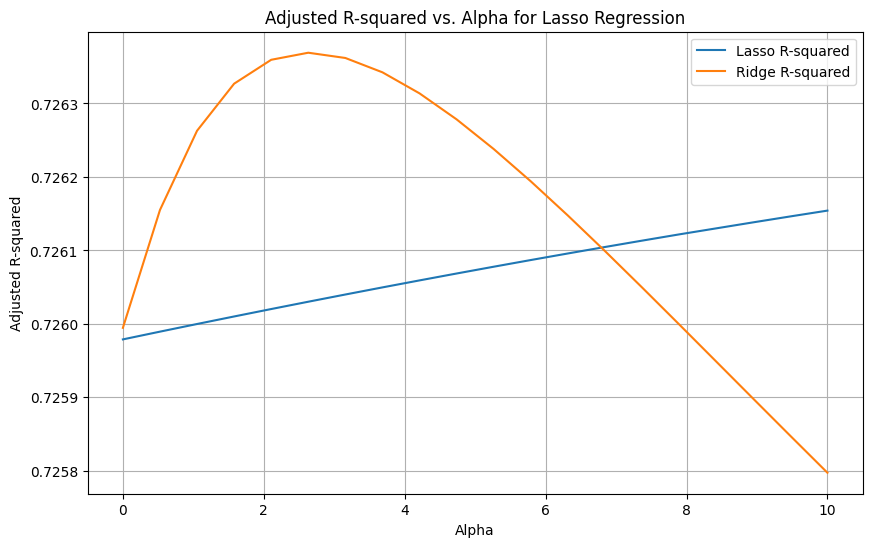

In [ ]:
alphas = np.linspace(0.00001, 10, 20)  # Adjust the range as needed

lasso_results = []
ridge_results = []

for alpha in alphas:
    lasso_model, lasso_test_metrics, lasso_train_metrics ,_ , _ = train_lasso(X_train, y_train, X_test, y_test, alpha=alpha)
    ridge_model, ridge_test_metrics, ridge_train_metrics ,_ , _ = train_ridge(X_train, y_train, X_test, y_test, alpha=alpha)
    lasso_results.append(lasso_test_metrics)
    ridge_results.append(ridge_test_metrics)


# plot the Adjusted R-squared values against the alpha values.
adjusted_r2_scores_lasso = [result['Adjusted R-squared'] for result in lasso_results]
adjusted_r2_scores_ridge = [result['Adjusted R-squared'] for result in ridge_results]

plt.figure(figsize=(10, 6))
plt.plot(alphas, adjusted_r2_scores_lasso , label='Lasso R-squared')
plt.plot(alphas, adjusted_r2_scores_ridge, label='Ridge R-squared')
plt.xlabel("Alpha")
plt.ylabel("Adjusted R-squared")
plt.title("Adjusted R-squared vs. Alpha for Lasso Regression")
plt.legend()
plt.grid(True)
plt.show()

## Random Forest

So far, we explored linear regression(with regularization). Now, it's time to investigate how powerful a random forest model could be in this task! We will search over a limited combination of hyperparameters manually(Sklearn's GridSearch took a lot of time and didn't run completely at the end). We will use k-fold cross validation to choose best hyperparameters.

In [ ]:
def train_random_forest(X_train, y_train, X_test, y_test, n_estimators=200, max_depth=10, random_state=42):
    model = RandomForestRegressor(n_estimators=n_estimators, max_depth=max_depth, random_state=random_state)
    model.fit(X_train, y_train)
    y_pred_test = model.predict(X_test)
    y_pred_train = model.predict(X_train)
    test_metrics, train_metrics = calculate_metrics(y_test, y_pred_test, y_train, y_pred_train, num_predictors=X_train.shape[1])
    return model, test_metrics, train_metrics , y_pred_test , y_pred_train

In [ ]:
def kfold_random_forest(X, y, n_splits=5, n_estimators_list=[50 , 100 , 150 , 200], max_depth_list=[5 , 10]):
    kf = KFold(n_splits=n_splits, shuffle=True, random_state=42)
    results = []

    for n_estimators in n_estimators_list:
        for max_depth in max_depth_list:
            fold_results = []
            ind = 1
            for train_index, test_index in kf.split(X):
                X_train1, X_val = X.iloc[train_index], X.iloc[test_index]
                y_train1, y_val = y.iloc[train_index], y.iloc[test_index]
                model, val_metrics, train_metrics , _ , _ = train_random_forest(
                    X_train1, y_train1, X_val, y_val,
                    n_estimators=n_estimators,
                    max_depth=max_depth
                )
                fold_results.append(val_metrics)
                ind += 1

            # Average the metrics across folds
            avg_metrics = {}
            for metric in fold_results[0]:
                avg_metrics[metric] = sum(fold[metric] for fold in fold_results) / len(fold_results)

            results.append({
                'n_estimators': n_estimators,
                'max_depth': max_depth,
                'avg_metrics': avg_metrics
            })
    return results


kfold_results = kfold_random_forest(X_train, y_train)

# Print or analyze the kfold_results
for result in kfold_results:
    print(f"n_estimators: {result['n_estimators']}, max_depth: {result['max_depth']}")
    print(result['avg_metrics'])
    print("-" * 20)

n_estimators: 50, max_depth: 5
{'MSE': 7706580152.294935, 'RMSE': 87773.58578308362, 'R-squared': 0.6742312205481371, 'Adjusted R-squared': 0.6733699074518593}
--------------------
n_estimators: 50, max_depth: 10
{'MSE': 5249397118.841843, 'RMSE': 72432.89952134571, 'R-squared': 0.7781274192707961, 'Adjusted R-squared': 0.777540800915596}
--------------------
n_estimators: 100, max_depth: 5
{'MSE': 7695126683.977567, 'RMSE': 87706.56297669055, 'R-squared': 0.6747306218548369, 'Adjusted R-squared': 0.6738706289241615}
--------------------
n_estimators: 100, max_depth: 10
{'MSE': 5227006447.844902, 'RMSE': 72277.49961101986, 'R-squared': 0.7790735431956375, 'Adjusted R-squared': 0.7784894262471018}
--------------------
n_estimators: 150, max_depth: 5
{'MSE': 7698632430.980276, 'RMSE': 87727.56683278535, 'R-squared': 0.674572245785076, 'Adjusted R-squared': 0.6737118340410213}
--------------------
n_estimators: 150, max_depth: 10
{'MSE': 5224351322.560101, 'RMSE': 72258.8046749352, 'R-squ

Now, let's find the best model's hyperparameters and train a new model with those params over the whole training dataset and evaluate on test set:

In [ ]:
best_dict = max(kfold_results, key=lambda x: x['avg_metrics']['Adjusted R-squared'])
print(f"highest Adjusted R-squared: {best_dict}")

highest Adjusted R-squared: {'n_estimators': 200, 'max_depth': 10, 'avg_metrics': {'MSE': 5218427124.966449, 'RMSE': 72217.28063466583, 'R-squared': 0.7794410543970466, 'Adjusted R-squared': 0.7788579091231824}}


Now that we have found the best parameters, we can train a random forest on whole dataset.

In [ ]:
# Train the Random Forest model
rf_model, rf_test_metrics, rf_train_metrics , rf_y_pred_test , rf_y_pred_train = train_random_forest(X_train, y_train, X_test, y_test , n_estimators=best_dict['n_estimators'] , max_depth=best_dict['max_depth'])

print("Random Forest Test Metrics:")
print_metrics(rf_test_metrics)
print("\nRandom Forest Train Metrics:")
print_metrics(rf_train_metrics)

Random Forest Test Metrics:
MSE: 5362704937.340311
RMSE: 73230.49185510303
R-squared: 0.7830923277283004
Adjusted R-squared: 0.7826338061629412

Random Forest Train Metrics:
MSE: 3518343129.5743237
RMSE: 59315.62298058011
R-squared: 0.8513291462531485
Adjusted R-squared: 0.8512507065860464


So far, random forest has the highest adjusted R-Squared amont our trained models:

In [ ]:
import random
def generate_random_color_names(size):
  color_names = ["skyblue", "lightcoral", "lightgreen", "gold" , "red", "orange", "yellow", "green", "blue", "indigo", "violet", "purple", "pink", "brown", "magenta"]
  return random.choices(color_names, k=size)

def compare_plot(models , adjusted_r2_scores , title="Adjusted R-squared"):
  plt.figure(figsize=(15, 6))
  colors = ['cyan' if val != max(adjusted_r2_scores) else 'red' for val in adjusted_r2_scores]
  plt.bar(models, adjusted_r2_scores , color = colors)
  plt.xlabel("Models")
  plt.ylabel(title)
  plt.title("Comparison of Model Performance (Adjusted R-squared)")
  plt.ylim(0, 1)  # Set y-axis limit for better visualization

  for i, v in enumerate(adjusted_r2_scores):
      plt.text(i, v + 0.01, f"{v:.4f}", ha='center')

  plt.show()
  pass


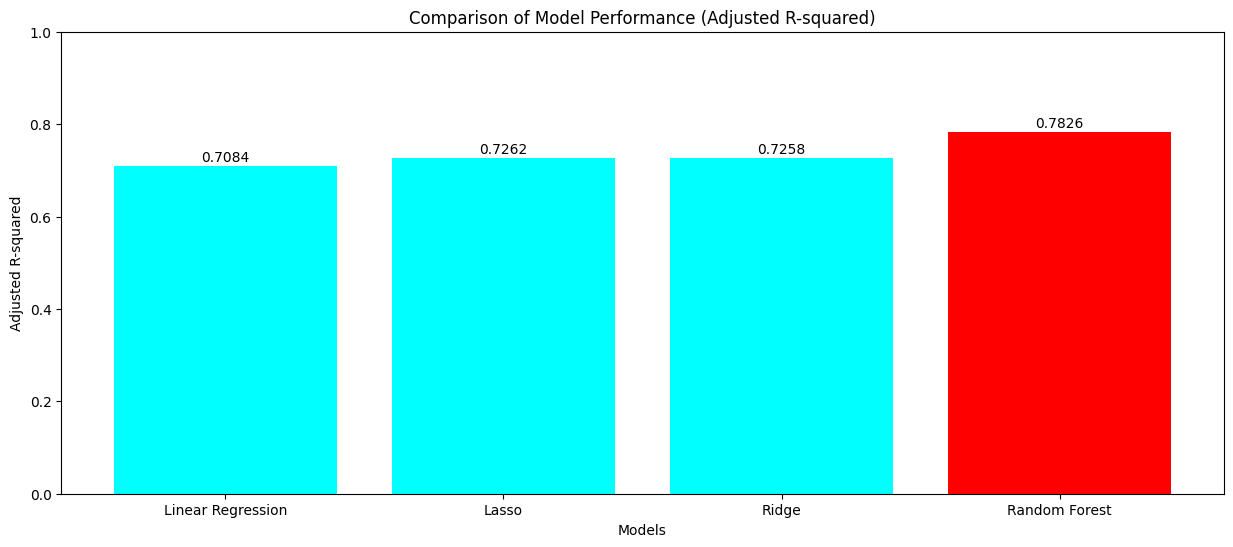

In [ ]:


models = ['Linear Regression', 'Lasso', 'Ridge', 'Random Forest']
adjusted_r2_scores = [
    lr_test_metrics['Adjusted R-squared'],
    lasso_test_metrics['Adjusted R-squared'],
    ridge_test_metrics['Adjusted R-squared'],
    rf_test_metrics['Adjusted R-squared']
]
compare_plot(models , adjusted_r2_scores)



## XGBoost
Again, we use k-fold + manual gridsearch over different hyperparametrs.

In [ ]:
def train_xgboost(X_train, y_train, X_test, y_test, num_boost_round = 100 , params=None ):
    base_params = {
        'objective': 'reg:squarederror',  # For regression
        'eval_metric': 'rmse',
    }
    if params is None:
        # append base param to another dict
        params = base_params.copy()
        params.update({
            'eta': 0.1,  # Learning rate
            'max_depth': 6,
        })
    else:
        base = base_params.copy()
        params.update(base_params.copy())

    dtrain = xgb.DMatrix(X_train, label=y_train)
    dtest = xgb.DMatrix(X_test, label=y_test)

    model = xgb.train(params, dtrain, num_boost_round=num_boost_round)

    y_pred_test = model.predict(dtest)
    y_pred_train = model.predict(dtrain)

    test_metrics , train_metrics = calculate_metrics(y_test, y_pred_test, y_train , y_pred_train, num_predictors=X_train.shape[1])
    return model, test_metrics, train_metrics , y_pred_test , y_pred_train

In [ ]:
def kfold_random_xgboost(X, y, n_splits=5, eta_list=[0.01 , 0.03 , 0.1], max_depth_list=[5 , 10] , num_boost_round_list = [100 , 200] ):
    kf = KFold(n_splits=n_splits, shuffle=True, random_state=42)
    results = []
    for eta in eta_list:
        for max_depth in max_depth_list:
            for num_boost_round in num_boost_round_list:
              print(f"eta: {eta}, max_depth: {max_depth}, num_boost_round: {num_boost_round}")
              fold_results = []
              ind = 1
              for train_index, test_index in kf.split(X):
                  X_train1, X_val = X.iloc[train_index], X.iloc[test_index]
                  y_train1, y_val = y.iloc[train_index], y.iloc[test_index]
                  model, val_metrics, train_metrics , _ , _ = train_xgboost(
                      X_train1, y_train1, X_val, y_val,
                      num_boost_round=num_boost_round,
                      params={'eta': eta, 'max_depth': max_depth}
                  )
                  fold_results.append(val_metrics)
                  ind += 1

              # Average the metrics across folds
              avg_metrics = {}
              for metric in fold_results[0]:
                  avg_metrics[metric] = sum(fold[metric] for fold in fold_results) / len(fold_results)

              results.append({
                  'eta': eta,
                  'max_depth': max_depth,
                  'num_boost_round': num_boost_round,
                  'avg_metrics': avg_metrics
              })
    return results


# usage
kfold_results = kfold_random_xgboost(X_train, y_train)



eta: 0.01, max_depth: 5, num_boost_round: 100
eta: 0.01, max_depth: 5, num_boost_round: 200
eta: 0.01, max_depth: 10, num_boost_round: 100
eta: 0.01, max_depth: 10, num_boost_round: 200
eta: 0.03, max_depth: 5, num_boost_round: 100
eta: 0.03, max_depth: 5, num_boost_round: 200
eta: 0.03, max_depth: 10, num_boost_round: 100
eta: 0.03, max_depth: 10, num_boost_round: 200
eta: 0.1, max_depth: 5, num_boost_round: 100
eta: 0.1, max_depth: 5, num_boost_round: 200
eta: 0.1, max_depth: 10, num_boost_round: 100
eta: 0.1, max_depth: 10, num_boost_round: 200


In [ ]:
# Print or analyze the kfold_results
for result in kfold_results:
    print(f"eta: {result['eta']}, max_depth: {result['max_depth']} , num_boost_round: {result['num_boost_round']}")
    print(result['avg_metrics'])
    print("-" * 20)

eta: 0.01, max_depth: 5 , num_boost_round: 100
{'MSE': 9551628488.040329, 'RMSE': 97710.4926982248, 'R-squared': 0.5964027780131291, 'Adjusted R-squared': 0.5953356916811077}
--------------------
eta: 0.01, max_depth: 5 , num_boost_round: 200
{'MSE': 6594634216.072683, 'RMSE': 81185.1627699136, 'R-squared': 0.7213578156246682, 'Adjusted R-squared': 0.7206211026036413}
--------------------
eta: 0.01, max_depth: 10 , num_boost_round: 100
{'MSE': 8027537513.093109, 'RMSE': 89565.9752162026, 'R-squared': 0.6608738368905687, 'Adjusted R-squared': 0.659977208270015}
--------------------
eta: 0.01, max_depth: 10 , num_boost_round: 200
{'MSE': 5313611954.691678, 'RMSE': 72871.13633096889, 'R-squared': 0.7755017150317929, 'Adjusted R-squared': 0.7749081552668071}
--------------------
eta: 0.03, max_depth: 5 , num_boost_round: 100
{'MSE': 5567078002.635154, 'RMSE': 74589.6356275989, 'R-squared': 0.7647783949199902, 'Adjusted R-squared': 0.7641564831896168}
--------------------
eta: 0.03, max_dep

In [ ]:
best_dict = max(kfold_results, key=lambda x: x['avg_metrics']['Adjusted R-squared'])
print(f"highest Adjusted R-squared: {best_dict}")

highest Adjusted R-squared: {'eta': 0.1, 'max_depth': 5, 'num_boost_round': 200, 'avg_metrics': {'MSE': 4243919004.711679, 'RMSE': 65112.152850719554, 'R-squared': 0.8207438703415889, 'Adjusted R-squared': 0.8202699276508495}}


In [ ]:
# Train the Random Forest model

xgb_model, xgb_val_metrics, xgb_train_metrics , xgb_y_pred_test , xgb_y_pred_train = train_xgboost(
                      X_train, y_train, X_test, y_test,
                      num_boost_round=best_dict['num_boost_round'],
                      params={'eta': best_dict['eta'], 'max_depth': best_dict['max_depth']}
                  )
print("XGBoost Test Metrics:")
print_metrics(xgb_val_metrics)

print("\nXGBoost Train Metrics:")
print_metrics(xgb_train_metrics)

XGBoost Test Metrics:
MSE: 4337550802.156275
RMSE: 65860.0850451643
R-squared: 0.8245571854410875
Adjusted R-squared: 0.8241863165219752

XGBoost Train Metrics:
MSE: 2678723389.6573515
RMSE: 51756.38501341986
R-squared: 0.8868080574789755
Adjusted R-squared: 0.8867483367060989


### Feature importance

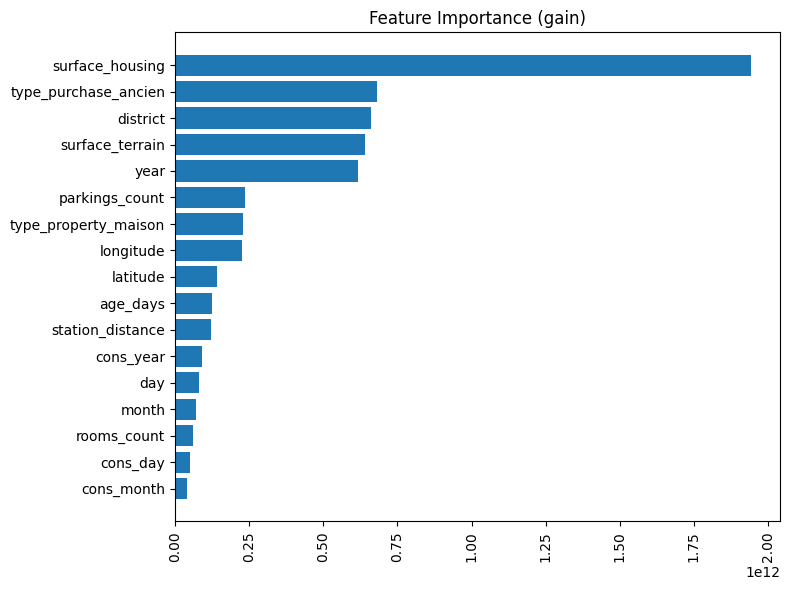

In [ ]:
fig, ax = plt.subplots(1, 1, figsize=(8, 6))

importance_types = ['gain']
for i, importance_type in enumerate(importance_types):
  importance = xgb_model.get_score(importance_type=importance_type)
  importance = dict(sorted(importance.items(), key=lambda item: item[1], reverse = False))

  features = list(importance.keys())
  values = list(importance.values())

  ax.barh(range(len(features)), values, tick_label=features)
  ax.set_title(f'Feature Importance ({importance_type})')
  ax.tick_params(axis='x', rotation=90)

plt.tight_layout()
plt.show()

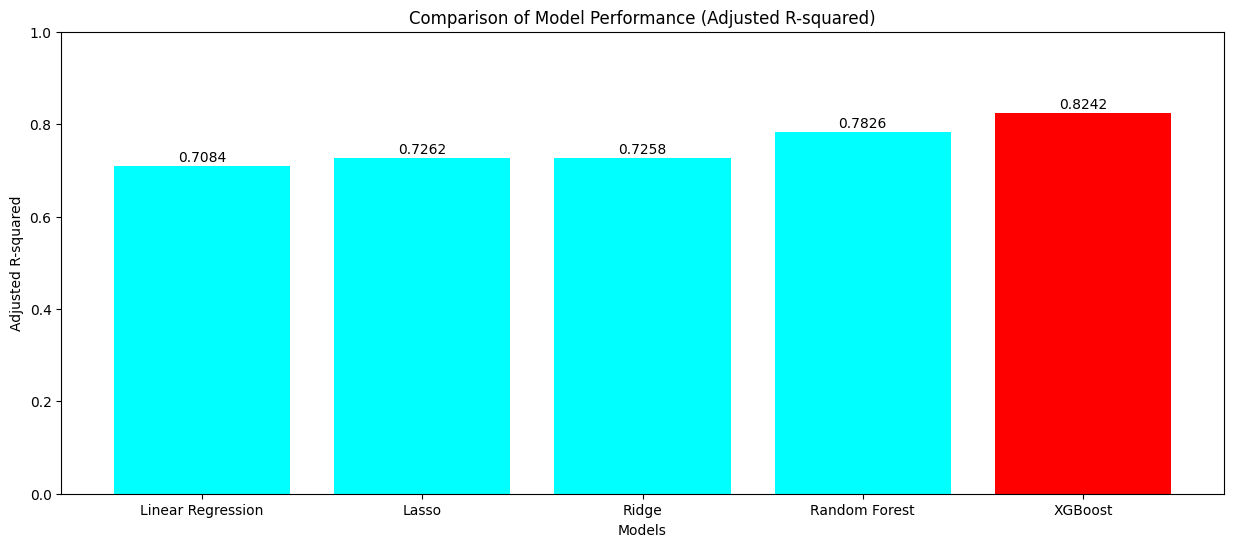

In [ ]:
if 'XGBoost' not in models:
    models.append('XGBoost')
    adjusted_r2_scores.append(xgb_val_metrics['Adjusted R-squared'])

compare_plot(models , adjusted_r2_scores)

## Neural network

For last model, I choose to train a neural network using keras. after several trials of different models with different hyperparameters, the following architecture is used:

1. a dense MLP with 5 hidden layers (4 * 128 + 1 * 64) and Relu activation fundtion.
2. a normalization layer at the beginning to normalize inputs.(Somehow like scalers in traditional ML algorithms)
3. Adam optimizer + power learning decay
4. Batch size 64
5. 100 epochs


In [ ]:
# Define a learning rate decay function
def lr_decay(epoch):
  initial_lr = 0.001 # initial learning rate
  decay_rate = 0.96  # decay rate
  decay_steps = 7   # decay steps

  lr = initial_lr * math.pow(decay_rate, math.floor((1+epoch)/decay_steps))
  return lr

def build_and_train_model(X_trainn, y_train, X_test, y_test, epochs=100, batch_size=64):
      # Create a Normalization layer

    X_train = X_trainn.values.astype(np.float32)
    norm_layer = Normalization(axis=-1)
    norm_layer.adapt(X_train)  # Adapt the normalization layer to your training data

    model = keras.Sequential([
        norm_layer,
        layers.Dense(128, activation='relu', input_shape=(X_train.shape[1],)),
        layers.Dense(128, activation='relu'),
        layers.Dense(128, activation='relu'),
        layers.Dense(128, activation='relu'),
        layers.Dense(64, activation='relu'),
        layers.Dense(1)  # Output layer for regression
    ])

    # model = keras.Sequential([
    #     norm_layer,
    #     layers.Dense(128, activation='relu', input_shape=(X_train.shape[1],)),
    #     BatchNormalization(), # Add BatchNormalization layer here
    #     layers.Dense(128, activation='relu'),
    #     layers.Dense(128, activation='relu'),
    #     layers.Dense(128, activation='relu'),
    #     layers.Dense(1)  # Output layer for regression
    # ])

    optimizer = Adam(learning_rate=0.001)  # Initial learning rate
    lr_scheduler = LearningRateScheduler(lr_decay)
    model.compile(optimizer=optimizer, loss='mse', metrics=[keras.metrics.R2Score])  # Mean Squared Error for regression

    history = model.fit(X_train, y_train, epochs=epochs, batch_size=batch_size, callbacks=[lr_scheduler], validation_split=0.2, verbose=1)

    y_pred_test = model.predict(X_test).flatten()
    y_pred_train = model.predict(X_train).flatten()

    test_metrics, train_metrics = calculate_metrics(y_test, y_pred_test, y_train, y_pred_train, num_predictors=X_train.shape[1])

    return model, history, test_metrics, train_metrics , y_pred_test , y_pred_train

# Example usage
nn_model, nn_history, nn_test_metrics, nn_train_metrics , nn_y_pred_test , nn_y_pred_train = build_and_train_model(X_train, y_train, X_test, y_test)

print("Neural Network Test Metrics:")
print_metrics(nn_test_metrics)

print("\nNeural Network Train Metrics:")
print_metrics(nn_train_metrics)


Epoch 1/100


/usr/local/lib/python3.11/dist-packages/keras/src/layers/core/dense.py:87: UserWarning:

Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.



403/403 ━━━━━━━━━━━━━━━━━━━━ 7s 10ms/step - loss: 49546792960.0000 - r2_score: -1.1747 - val_loss: 7581486592.0000 - val_r2_score: 0.6931 - learning_rate: 0.0010
Epoch 2/100
403/403 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 7370707456.0000 - r2_score: 0.6970 - val_loss: 6812337664.0000 - val_r2_score: 0.7242 - learning_rate: 0.0010
Epoch 3/100
403/403 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 6505236480.0000 - r2_score: 0.7227 - val_loss: 6712397312.0000 - val_r2_score: 0.7282 - learning_rate: 0.0010
Epoch 4/100
403/403 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - loss: 6016677888.0000 - r2_score: 0.7378 - val_loss: 6494735872.0000 - val_r2_score: 0.7371 - learning_rate: 0.0010
Epoch 5/100
403/403 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 6606025216.0000 - r2_score: 0.7368 - val_loss: 6466526720.0000 - val_r2_score: 0.7382 - learning_rate: 0.0010
Epoch 6/100
403/403 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 5866877952.0000 - r2_score: 0.7416 - val_loss: 6414762496.0000 - val_r2_score: 0.7403 - learn

### Training history plto

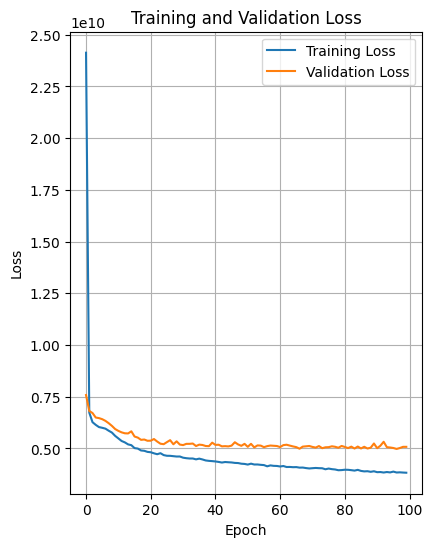

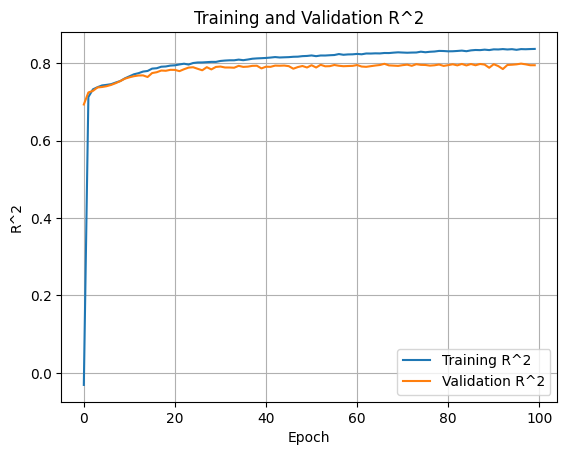

In [ ]:
plt.figure(figsize=(10, 6))
plt.subplot(1, 2, 1)
plt.plot(nn_history.history['loss'], label='Training Loss')
plt.plot(nn_history.history['val_loss'], label='Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Training and Validation Loss')
plt.legend()
plt.grid(True)
plt.show()

plt.plot(nn_history.history['r2_score'], label='Training R^2')
plt.plot(nn_history.history['val_r2_score'], label='Validation R^2')
plt.xlabel('Epoch')
plt.ylabel('R^2')
plt.title('Training and Validation R^2')
plt.legend()
plt.grid(True)
plt.show()

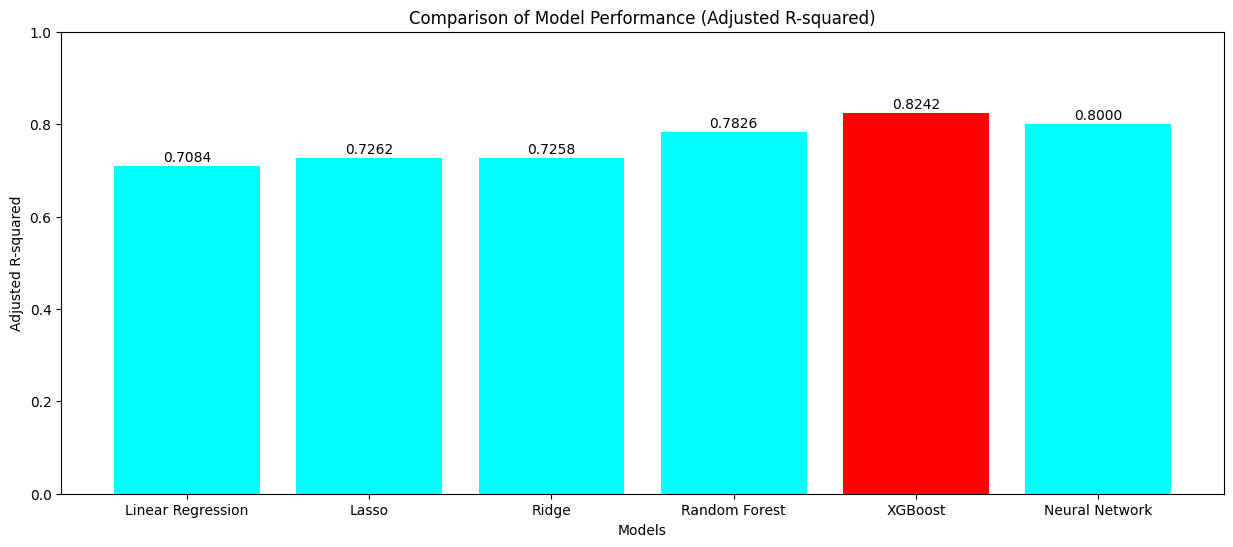

In [ ]:
if 'Neural Network' not in models:
    models.append('Neural Network')
    adjusted_r2_scores.append(nn_test_metrics['Adjusted R-squared'])

compare_plot(models , adjusted_r2_scores)

# Ensemble of previous models

At the end let's combine our trained models together. we will define two separate combination.

1. the first combination simply calculates a weighted average of previous models outputs. The weights are simply chosen based on the adjusted R2 score of models.

2. for the second combination, we will define a stacking models that inputs the training results of our models and trains itself on this data.

In [ ]:
adjusted_r2_scores

[0.7084109514414971,
 0.726154163433448,
 0.7257974564109213,
 0.7826338061629412,
 0.8241863165219752,
 0.799999686202991]

## Aggregated ensemble

In [ ]:
def weighted_average_prediction(models, predictions, coefficients):
    if not (len(models) == len(predictions) == len(coefficients)):
        raise ValueError("The lengths of models, predictions, and coefficients lists must be the same.")

    predictions = [np.array(pred) for pred in predictions]

    weighted_pred = np.average(predictions, axis=0, weights=coefficients)

    return weighted_pred

# remove LR from data
if 'Linear Regression' in models:
  models.remove('Linear Regression')
  adjusted_r2_scores.remove(lr_test_metrics['Adjusted R-squared'])


# Assuming all predictions for each model stored in these variables
predictions_test = [lasso_y_pred_test, ridge_y_pred_test, rf_y_pred_test, xgb_y_pred_test, nn_y_pred_test]
predictions_train = [lasso_y_pred_train, ridge_y_pred_train, rf_y_pred_train, xgb_y_pred_train, nn_y_pred_train]

adjusted_r2_scores_train = {
    'Lasso': lasso_train_metrics['Adjusted R-squared'],
    'Ridge': ridge_train_metrics['Adjusted R-squared'],
    'Random Forest': rf_train_metrics['Adjusted R-squared'],
    'XGBoost': xgb_train_metrics['Adjusted R-squared'],
    'Neural Network': nn_train_metrics['Adjusted R-squared']
}
adjusted_r2_scores_train = [adjusted_r2_scores_train[model] for model in models]

# Normalize the coefficient to sum to 1
coefficients_test = np.array(adjusted_r2_scores) / np.sum(adjusted_r2_scores)
coefficients_train = np.array(adjusted_r2_scores_train) / np.sum(adjusted_r2_scores_train)


# Calculate the weighted average prediction
weighted_prediction_test = weighted_average_prediction(models, predictions_test, coefficients_test)
weighted_prediction_train = weighted_average_prediction(models, predictions_train, coefficients_train)

In [ ]:
aggregated_test_metrics, aggregated_train_metrics = calculate_metrics(y_test, weighted_prediction_test, y_train, weighted_prediction_train, num_predictors=X_train.shape[1])
print("Aggregated Test Metrics:")
print_metrics(aggregated_test_metrics)

print("\nAggregated Train Metrics:")
print_metrics(aggregated_train_metrics)



Aggregated Test Metrics:
MSE: 4861789486.807314
RMSE: 69726.53359236578
R-squared: 0.8033530740586643
Adjusted R-squared: 0.8029373817257865

Aggregated Train Metrics:
MSE: 3777918214.1566224
RMSE: 61464.77213946719
R-squared: 0.8403605601843614
Adjusted R-squared: 0.8402763334230299


## Stacking ensemble

In this model, I combine the final training result of previous models to create a new dataset. Then this dataset is given to 2 different meta-learner model: A linear regression model, and an XGB model(just to have the final comparison).
We drop our first basic model(simple linear regression) and instead use ridge and lasso results.


In [ ]:
stacked_train_data = pd.DataFrame({
    'Lasso': predictions_train[0],
    'Ridge': predictions_train[1],
    'RandomForest': predictions_train[2],
    'XGBoost': predictions_train[3],
    'NeuralNetwork': predictions_train[4]
})

stacked_test_data = pd.DataFrame({
    'Lasso': predictions_test[0],
    'Ridge': predictions_test[1],
    'RandomForest': predictions_test[2],
    'XGBoost': predictions_test[3],
    'NeuralNetwork': predictions_test[4]
})
stacked_train_data.head()

,Lasso,Ridge,RandomForest,XGBoost,NeuralNetwork
0,203264.484720,203320.048365,187152.294115,196074.828125,201679.156250
1,381003.489838,381236.636730,433830.677030,450769.437500,472042.781250
2,334216.099985,334562.533194,236418.242646,252592.281250,301327.906250
3,127540.974714,127580.045156,180339.665272,183413.750000,175967.234375
4,184140.712247,184044.046318,222312.241897,224683.984375,211747.156250


In [ ]:
# Train a linear regression model on the stacked data
stacking_model = LinearRegression()
stacking_model.fit(stacked_train_data, y_train)

# Make predictions using the stacking model
stacked_predictions_test = stacking_model.predict(stacked_test_data)
stacked_predictions_train = stacking_model.predict(stacked_train_data)


# Evaluate the stacking model
stacked_test_metrics, stacked_train_metrics = calculate_metrics(y_test, stacked_predictions_test, y_train, stacked_predictions_train, num_predictors=X_train.shape[1])

print("Stacked Test Metrics:")
print_metrics(stacked_test_metrics)

print("\nStacked Train Metrics:")
print_metrics(stacked_train_metrics)


Stacked Test Metrics:
MSE: 4454438321.534538
RMSE: 66741.57865629594
R-squared: 0.8198293848176718
Adjusted R-squared: 0.8194485217912978

Stacked Train Metrics:
MSE: 2596382730.185415
RMSE: 50954.71254148545
R-squared: 0.8902874384520453
Adjusted R-squared: 0.8902295534222102


In [ ]:
xgb_model_ensemble, xgb_val_metrics_ensemble, xgb_train_metrics_ensemble , xgb_y_pred_test_ensemble , xgb_y_pred_train_ensemble = train_xgboost(
                      stacked_train_data, y_train, stacked_test_data, y_test,
                      num_boost_round=best_dict['num_boost_round'],
                      params={'eta': best_dict['eta'], 'max_depth': best_dict['max_depth']}
                  )
print("XGBoost Test Metrics:")
print_metrics(xgb_val_metrics)

print("\nXGBoost Train Metrics:")
print_metrics(xgb_train_metrics)

XGBoost Test Metrics:
MSE: 4337550802.156275
RMSE: 65860.0850451643
R-squared: 0.8245571854410875
Adjusted R-squared: 0.8241863165219752

XGBoost Train Metrics:
MSE: 2678723389.6573515
RMSE: 51756.38501341986
R-squared: 0.8868080574789755
Adjusted R-squared: 0.8867483367060989


## Plot final results

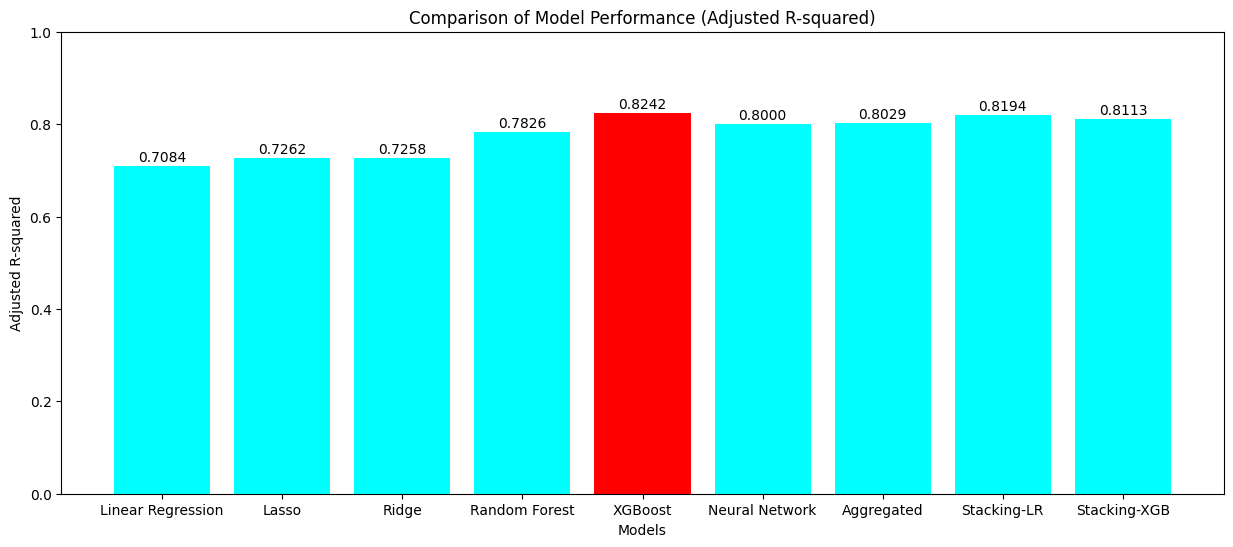

In [ ]:
if 'Linear Regression' not in models:
    models.insert(0 , 'Linear Regression')
    adjusted_r2_scores.insert(0, lr_test_metrics['Adjusted R-squared'])
if 'Aggregated' not in models:
    models.append('Aggregated')
    adjusted_r2_scores.append(aggregated_test_metrics['Adjusted R-squared'])
if 'Stacking' not in models:
    models.append('Stacking-LR')
    adjusted_r2_scores.append(stacked_test_metrics['Adjusted R-squared'])
if 'Stacking' not in models:
    models.append('Stacking-XGB')
    adjusted_r2_scores.append(xgb_val_metrics_ensemble['Adjusted R-squared'])

compare_plot(models , adjusted_r2_scores)

As you can see from the chart above, the XGB model outperforms other models(even neural network and stacking models). This shows the great potential of XGB model.

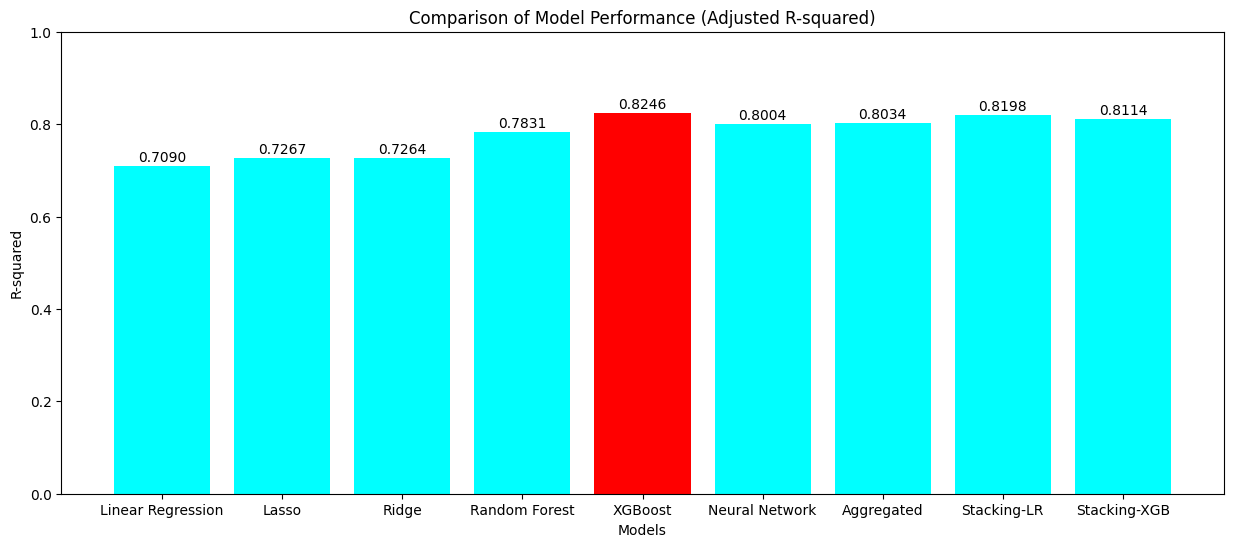

In [ ]:
r2_scores = [lr_test_metrics['R-squared'],
             lasso_test_metrics['R-squared'],
             ridge_test_metrics['R-squared'],
             rf_test_metrics['R-squared'],
             xgb_val_metrics['R-squared'],
             nn_test_metrics['R-squared'],
             aggregated_test_metrics['R-squared'],
             stacked_test_metrics['R-squared'],
             xgb_val_metrics_ensemble['R-squared']]
compare_plot(models , r2_scores , title = "R-squared")

## Conclusion

This study focused on modeling and predicting housing prices in Lyon using various regression techniques, spanning from simple linear models to advanced machine learning algorithms and ensemble methods. The models evaluated included Linear Regression, Lasso, Ridge, Random Forest, XGBoost, Neural Networks, aggregated models, and stacking ensembles with both Linear Regression and XGBoost as base learners.

The performance of each model was assessed using the adjusted R-squared metric to ensure a balance between goodness-of-fit and model complexity. The results revealed a clear trend: advanced machine learning models and ensemble approaches outperformed simpler linear models, demonstrating their ability to better capture the complexity of the data.

The traditional methods—Linear Regression, Lasso, and Ridge—yielded adjusted R-squared values of **0.7090**, **0.7267**, and **0.7264**, respectively. While these methods are computationally efficient and interpretable, their performance was comparatively limited, likely due to their inability to model non-linear relationships in the data.

Random Forest achieved an adjusted R-squared of **0.7831**, showing its effectiveness in handling non-linearities and feature interactions. Neural Networks and aggregated models performed better, with adjusted R-squared values of **0.8004** and **0.8034**, respectively. However, XGBoost emerged as the best single model, achieving the highest adjusted R-squared of **0.8246**, indicating its strong ability to model complex patterns in the housing dataset.

Further improvements were observed with stacking ensemble models. The stacking ensemble using Linear Regression as the meta-learner achieved an adjusted R-squared of **0.8198**, while stacking with XGBoost as the meta-learner achieved **0.8114**. These results suggest that ensemble approaches can further enhance predictive accuracy by combining the strengths of multiple models.

### Implications

The findings highlight the value of leveraging advanced machine learning models and ensemble techniques for housing price prediction tasks. While linear models remain useful for their interpretability, they may not suffice for datasets with complex relationships and non-linear interactions. XGBoost and ensemble methods, on the other hand, offer superior performance, making them ideal for applications where accuracy is paramount.

### Limitations and Future Directions

Although the results are promising, this analysis has limitations. Additional features, such as socioeconomic indicators, proximity to amenities, and geographic details, could further improve model performance, which requires gathering more data to enrich our dataset's features. Additionally, fine-tuning hyperparameters, especially for Neural Networks, XGBoost, and ensemble models, may yield even better results. Future studies could also explore explainability techniques to bridge the gap between interpretability and the high accuracy of advanced models.

In conclusion, this analysis underscores the importance of advanced regression methods, particularly XGBoost and stacking ensembles, in modeling housing prices in Lyon. The insights from this study provide a strong foundation for further research and practical applications in real estate analytics.
